# Softmax (Multinomial Logistic) Regression, studied from first principles
### ML Assignment A2 · Option 1 — *Study a fundamental machine-learning model*
**Student:** `<STUDENT NAME>` · **ID:** `<STUDENT ID>` · UTS, `<YEAR>`  &nbsp;|&nbsp; **Notebook URL (plain text for the journal PDF):** `<paste the public Colab URL here>`

> **What is this?** A from-scratch NumPy implementation and empirical/theoretical study of the *softmax regression* classifier (the multiclass generalisation of logistic regression) on **Fashion-MNIST**. *No machine-learning library implements any part of the model, loss, gradient, optimisers, metrics or cross-validation.* `scikit-learn`/`scipy` appear only (i) to download a fallback copy of the data if the primary mirror fails, (ii) in clearly labelled **verification** cells (cross-check against `LogisticRegression`, Spearman correlation), and (iii) one clearly-labelled off-the-shelf reference MLP at the end.

**How to run:** *Runtime → Run all* (CPU is enough; ≈ 10–25 min depending on the number of cores). The notebook is self-contained: it downloads the data, pre-processes it, trains, evaluates, saves figures to `figs_opt1/` and all numbers to `results_opt1.json`. Everything is seeded (`SEED = 2025`).

#### Map of this notebook to the marking criteria
| Criterion (A2 spec §4) | Where |
|---|---|
| **A – Task definition** (I/O at the *Clear* level, motivation/history, research question) | §A |
| **B – Model, algorithm, key components, theory-to-code, implementation challenges** | §B (model, loss, gradient, Hessian, optimisers, L-BFGS, verification) |
| **C – Evaluation & refinement** (expected behaviour, loss-vs-objective, validation scheme, error analysis, custom metric, reflections) | §C |
| Clarifications: algorithm implemented (not imported) · self-contained · proper validation scheme | all cells; CV in §C.1 |


In [1]:
import os, gzip, json, time, math, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt

SEED = 2025
FIG_DIR = "figs_opt1"; os.makedirs(FIG_DIR, exist_ok=True)
RESULTS = {}                      # every number quoted in the report is stored here -> results_opt1.json
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
K, D = 10, 784
print("numpy", np.__version__)


numpy 2.4.6


---
# A. Task definition

### A.1 The learning task at the technical level
We study the **supervised, 10-class image-classification task** *"which garment category is shown in this picture?"* with the model class $f_\theta(x)=\mathrm{softmax}(W^\top x+b)$.

| | **Training phase** | **Deployment phase** |
|---|---|---|
| **Input** | Matrix $X\in\mathbb R^{n\times 784}$ ($n=50{,}000$). Each row is a $28\times28$ **greyscale** product image flattened row-major; raw entries are integers in $\{0,\dots,255\}$ (0 = black background). Pre-processing: $\tilde x=(x/255-\mu)/\sigma$ where $\mu\in\mathbb R^{784}$ is the *per-pixel training mean* and $\sigma\in\mathbb R$ is *one global training standard deviation* (≈ 0.295 on the $[0,1]$ scale; printed below). The images are Zalando catalogue photographs, centred, front-view, background removed – i.e. *not* photographs "in the wild". | One image $x\in\{0,\dots,255\}^{28\times28}$, passed through the **same** frozen $(\mu,\sigma)$ transform. Images outside the catalogue distribution (rotated, cluttered, colour photographs) are out of scope. |
| **Labels / Output** | $y\in\{0,\dots,9\}$ (T-shirt, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot), encoded as one-hot $e_y\in\{0,1\}^{10}$. The classes are balanced ($\approx$5,000 each). | A **probability vector** $q\in\Delta^{9}$ ($q_k\ge0,\ \sum_kq_k=1$), $q_k=\Pr(\text{class }k\mid x)$ under the model, and the decision $\hat y=\arg\max_k q_k$ (or the minimum-expected-cost class, §C.6). |
| **Compared with** | model output $q$ vs. one-hot $e_y$ through the *training loss* (cross-entropy, a convex surrogate). | $\hat y$ vs. true label through the **task objective**: 0-1 error (and an illustrative cost-weighted error, §C.6); $q$ vs. outcomes through calibration (ECE). |

*Splits:* 60,000 official training images → **50,000 train / 10,000 validation** (random, seeded); the official **10,000 test** images are touched only for final reporting. 

*Core technical challenges:* (i) four upper-body classes (T-shirt / Shirt / Pullover / Coat) are visually near-identical, so the Bayes error of a *linear* model is far from 0; (ii) pixel intensities are strongly correlated ⇒ an **ill-conditioned** optimisation problem (§B.5); (iii) the softmax parametrisation is **over-complete** (adding the same vector to every class column changes nothing) ⇒ the loss is convex but *not strictly* convex; (iv) the training loss (cross-entropy) is **not** the quantity we ultimately care about (0-1 error / calibrated decisions) – the central theme of this study.

### A.2 Motivation and historical perspective
*Why study this model?* Softmax regression is the **simplest model in which every ingredient of the modern ML pipeline is visible and analysable in closed form**: a hypothesis space (a linear-in-features probability model), a loss with an information-theoretic meaning, a convex optimisation problem, a generalisation bound that depends on a norm, and an output that is a calibrated-able probability. The last layer of virtually every deep classifier *is* a softmax regression on learned features, so understanding it exactly transfers to deep networks.

*History.* **Berkson (1944)** introduced the *logit* for bio-assay; **Cox (1958)** formalised logistic regression for binary sequences; the multi-class version appears as the *multinomial logit* in **Theil (1969)** and **McFadden (1974)**. In parallel **Rosenblatt's perceptron (1958)** gave a mistake-driven linear classifier with no probabilistic semantics. **Jaynes' maximum-entropy principle (1957)** later showed that softmax regression is *exactly* the maximum-entropy distribution matching the empirical feature moments – the same model, derived from information theory (applied to NLP by Berger et al., 1996). **Bridle (1990)** coined "softmax" and showed that training a feed-forward net with cross-entropy yields posterior probabilities. Statistical learning theory then asked *why minimising a convex surrogate is legitimate*: **Zhang (2004)** and **Bartlett, Jordan & McAuliffe (2006)** proved that, for classification-calibrated surrogates such as cross-entropy, driving the surrogate excess risk to 0 drives the 0-1 excess risk to 0 – but only *in the limit of unrestricted function classes and infinite data*. **Bartlett & Mendelson (2002)** and **Kakade, Sridharan & Tewari (2008)** gave norm-based generalisation bounds ($\propto B R/\sqrt n$) for linear predictors, and **Soudry et al. (2018)** showed that on separable data gradient descent on the logistic/softmax loss has an *implicit bias* towards the max-margin solution while $\|W\|\to\infty$ only logarithmically. **Guo et al. (2017)** documented that cross-entropy-trained models are mis-calibrated and proposed temperature scaling; **Zhang & Sabuncu (2018)** and **Ghosh et al. (2017)** studied bounded losses that are robust to label noise.

*Why machine learning rather than hand-written rules?* There is no closed-form rule mapping 784 correlated intensities to "Coat" vs "Shirt"; but labelled examples are cheap (60k), i.i.d. from a stable catalogue distribution – the conditions under which empirical risk minimisation is justified.
*Why a **linear** model instead of a CNN?* Deliberately: a linear model is the object of study. It is convex, so optimisation questions can be separated from modelling questions; its capacity is explicitly controlled by $\|W\|$, so theory can be *tested*; and its remaining error (≈ 15 %) quantifies what non-linear features buy (§C.5).

### A.3 Research question and testable hypotheses
> **RQ.** *How faithfully does minimising the convex cross-entropy surrogate (with an L2 penalty, solved by first/quasi-second-order methods) track the quantities we actually care about — 0-1 error, cost-weighted error and probability calibration — and which mechanisms (capacity/norm, optimisation path, loss shape) control the gap, both between train and test and between loss and objective?*

* **H1 (capacity).** The generalisation gap is governed by the norm-based complexity $\|W\|_F\,R/\sqrt n$ (Rademacher bound), *not* by the raw number of parameters (7,850).
* **H2 (loss ≠ objective).** Cross-entropy is far more sensitive than 0-1 error to over-fitting and to a monotone re-scaling of the logits; hence low CE is neither necessary nor sufficient for low error, and the mismatch is measurable and *fixable post hoc* (temperature scaling).
* **H3 (optimisation as regulariser).** On separable data with $\lambda=0$ the loss is never minimised: $\|W\|$ grows like $\log t$ and the normalised margin increases (Soudry et al.), so *when we stop* is a hyper-parameter.
* **H4 (customising the loss).** Under symmetric label noise a bounded variant of cross-entropy (generalised CE) is more robust than CE, at essentially no cost on clean data.


shapes: (50000, 784) (10000, 784) (10000, 784) | train class counts: [5000 4983 4989 5013 5053 5006 4972 5027 4962 4995]


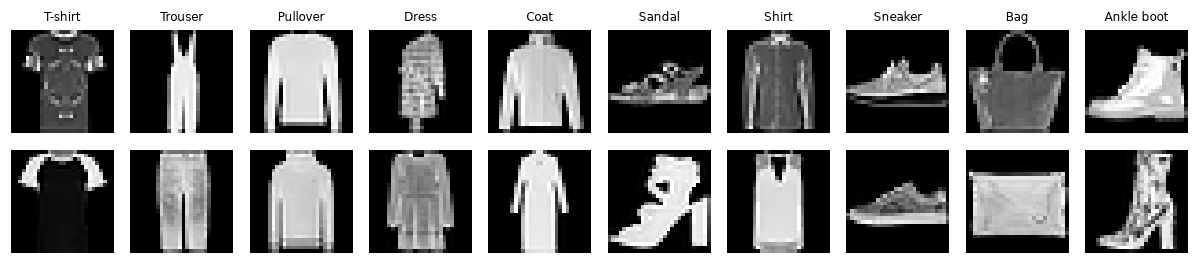

In [2]:
BASE = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"   # Fashion-MNIST idx files (Zalando Research)
FILES = dict(xtr="train-images-idx3-ubyte.gz", ytr="train-labels-idx1-ubyte.gz",
             xte="t10k-images-idx3-ubyte.gz", yte="t10k-labels-idx1-ubyte.gz")
def fetch(fname):
    os.makedirs("data", exist_ok=True); path = os.path.join("data", fname)
    if not os.path.exists(path): urllib.request.urlretrieve(BASE + fname, path)
    with open(path, "rb") as f: return gzip.decompress(f.read())

def load_fashion_mnist():
    try:
        xtr = np.frombuffer(fetch(FILES["xtr"]), np.uint8, offset=16).reshape(-1, D)
        ytr = np.frombuffer(fetch(FILES["ytr"]), np.uint8, offset=8).astype(int)
        xte = np.frombuffer(fetch(FILES["xte"]), np.uint8, offset=16).reshape(-1, D)
        yte = np.frombuffer(fetch(FILES["yte"]), np.uint8, offset=8).astype(int)
    except Exception as e:                      # fallback mirror
        print("direct download failed (", e, ") -> trying OpenML")
        from sklearn.datasets import fetch_openml
        Xa, ya = fetch_openml("Fashion-MNIST", version=1, return_X_y=True, as_frame=False)
        xtr, ytr, xte, yte = Xa[:60000].astype(np.uint8), ya[:60000].astype(int), Xa[60000:].astype(np.uint8), ya[60000:].astype(int)
    return xtr, ytr, xte, yte

Xtr_raw, ytr_all, Xte_raw, yte = load_fashion_mnist()
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(Xtr_raw))
val_idx, tr_idx = perm[:10_000], perm[10_000:]          # 50k train / 10k validation / 10k official test

# pre-processing: scale to [0,1], subtract the per-pixel TRAIN mean, divide by ONE global TRAIN std (keeps geometry, no noise amplification)
mu = (Xtr_raw[tr_idx] / 255.0).mean(0)
sigma = (Xtr_raw[tr_idx] / 255.0 - mu).std()
def prep(Xu8): return (Xu8 / 255.0 - mu) / sigma        # float64, shape (n, 784)
Xtr, ytr = prep(Xtr_raw[tr_idx]), ytr_all[tr_idx]
Xva, yva = prep(Xtr_raw[val_idx]), ytr_all[val_idx]
Xte = prep(Xte_raw)
print("shapes:", Xtr.shape, Xva.shape, Xte.shape, "| train class counts:", np.bincount(ytr))
RESULTS["data"] = dict(n_train=len(ytr), n_val=len(yva), n_test=len(yte), global_std=float(sigma),
                       max_row_norm_train=float(np.linalg.norm(Xtr, axis=1).max()))

fig, ax = plt.subplots(2, 10, figsize=(11, 2.6))
for k in range(10):
    for r in range(2):
        i = np.where(ytr == k)[0][r]; ax[r, k].imshow(Xtr_raw[tr_idx][i].reshape(28, 28), cmap="gray"); ax[r, k].axis("off")
    ax[0, k].set_title(CLASSES[k], fontsize=8)
savefig("fig00_samples"); plt.show()


---
# B. Model, algorithm and system structure

### B.1 System overview (data flow)
```
 raw 28x28 uint8 ──► x/255 ──► (x − μ_train)/σ_train ──► z = Wᵀx̃ + b ──► q = softmax(z) ──► ŷ = argmax q   (or argmin_k Σ_j q_j C[j,k])
                      │ training only:
                      └─► objective  J(θ) = (1/n) Σ_i ℓ(z_i, y_i) + (λ/2)‖W‖²_F ──► ∇J (analytic) ──► optimiser (GD / momentum / Adam / L-BFGS) ──► θ*
                                          validation set ──► λ (5-fold CV), temperature T, early-stopping diagnostics;   test set ──► reported once
```

### B.2 Model (hypothesis space)
$$\mathcal H=\Big\{x\mapsto q(x;W,b)=\mathrm{softmax}(W^\top x+b)\ :\ W\in\mathbb R^{784\times10},\ b\in\mathbb R^{10}\Big\},\qquad \mathrm{softmax}(z)_k=\frac{e^{z_k}}{\sum_je^{z_j}}$$
It is a **parametrised family of functions** $\mathbb R^{784}\to\Delta^9$ with $7{,}850$ parameters. *Why this form?* (1) Modelling the **log-odds as linear**, $\log\frac{q_k}{q_j}=(w_k-w_j)^\top x+(b_k-b_j)$, is the unique choice that makes the class-conditional distributions exponential-family with a shared dispersion (generalised linear model); (2) it is the **max-entropy** distribution consistent with the empirical feature moments; (3) its negative log-likelihood is convex. *Shift invariance:* $\mathrm{softmax}(z+c\mathbf 1)=\mathrm{softmax}(z)$, hence adding any vector $v$ to every column of $W$ (and any scalar to $b$) leaves $q$ unchanged ⇒ **$785$ flat directions** in the *unregularised* loss. The L2 penalty removes them (picks the minimum-norm representative).

### B.3 Loss, objective and gradient (theory → code)
For a sample $(x,y)$ with logits $z=W^\top x+b$ the **cross-entropy** is
$$\ell_{\rm CE}(z,y)=-\log q_y=-z_y+\log\!\sum_je^{z_j}=H(e_y,q)=\mathrm{KL}(e_y\,\|\,q)\quad(\text{because }H(e_y)=0),$$
so **empirical-risk minimisation of CE = maximum likelihood = minimising the KL divergence from the empirical label distribution to the model** (verified numerically below). Differentiating through the log-sum-exp gives the remarkably simple
$$\frac{\partial \ell_{\rm CE}}{\partial z}=q-e_y\quad\Longrightarrow\quad \nabla_WJ=\tfrac1nX^\top(Q-Y)+\lambda W,\qquad \nabla_bJ=\tfrac1n\mathbf 1^\top(Q-Y).$$
At an unregularised optimum $X^\top(Q-Y)=0$: *the model's expected feature vector per class equals the empirical one* (moment matching = the dual max-entropy condition).

**Hessian.** $\nabla^2_\theta J=\frac1n\sum_i\big(\mathrm{diag}(q_i)-q_iq_i^\top\big)\otimes\tilde x_i\tilde x_i^\top\ \succeq0$, where $\tilde x=(x,1)$; the first factor is the covariance of a categorical variable ⇒ PSD ⇒ **$J$ is convex**; its largest eigenvalue is $\le\tfrac12$, so $\nabla^2J\preceq\big(\tfrac12\lambda_{\max}(\tfrac1n\tilde X^\top\tilde X)+\lambda\big)I=:L\,I$ ⇒ **$L$-smooth**, and $\nabla^2J\succeq\lambda I$ off the null-space ⇒ **$\mu\!=\!\lambda$-strongly convex** (modulo the shift directions). This gives a *principled step size* $1/L$ and a *condition number* $\kappa\le L/\lambda$ (§B.5).

**Customised loss (H4).** Generalised cross-entropy (Zhang & Sabuncu 2018) $\ell_q=\frac{1-q_y^{\,q}}{q}$ interpolates between CE ($q\!\to\!0$, since $\frac{1-p^q}{q}\to-\log p$) and the noise-robust but slow-to-train MAE ($q=1$). Its logit-gradient is $\partial\ell_q/\partial z_j=q_y^{\,q}\,(q_j-\mathbb 1[j=y])$ = **the CE gradient re-weighted by $q_y^{\,q}$**, i.e. samples the model finds very unlikely (candidate mislabels) get down-weighted. I derived this gradient myself and verified it by finite differences (below).

| Maths | Code |
|---|---|
| $\mathrm{softmax},\ \log\mathrm{softmax}$ (log-sum-exp shift for stability) | `softmax`, `log_softmax` |
| $\ell_{\rm CE}$, $\partial\ell/\partial z=(q-e_y)/n$ | `ce_loss_grad` |
| $\ell_q$, $\partial\ell/\partial z=q_y^{\,q}(q-e_y)/n$ | `gce_loss_grad` |
| $J(\theta)$, $\nabla J$ (chain rule through $z=\tilde X\theta$) | `make_objective` |
| GD / heavy-ball / Adam updates | `GD`, `Momentum`, `Adam`, `fit_first_order` |
| two-loop recursion, Armijo line search | `lbfgs` |
| 0-1 error, macro-F1, Brier, ECE, confusion | `evaluate`, `confusion`, `macro_f1`, `ece_score` |


In [3]:
def log_softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)                 # shift invariance -> numerical stability (log-sum-exp trick)
    return Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))
def softmax(Z): return np.exp(log_softmax(Z))

def ce_loss_grad(Z, y):
    """mean cross-entropy and dLoss/dZ = (P - Y)/n."""
    n = len(y); logp = log_softmax(Z); loss = -logp[np.arange(n), y].mean()
    G = np.exp(logp); G[np.arange(n), y] -= 1.0
    return loss, G / n

def gce_loss_grad(Z, y, q=0.7):
    """Generalised cross-entropy (Zhang & Sabuncu 2018): L_q = (1 - p_y^q)/q.   dL/dz_j = p_y^q (p_j - 1[j=y])."""
    n = len(y); P = softmax(Z); py = P[np.arange(n), y]
    loss = ((1.0 - py ** q) / q).mean()
    G = (py ** q)[:, None] * P; G[np.arange(n), y] -= py ** q
    return loss, G / n

def make_objective(X, y, lam, loss_grad):
    """theta = [vec(W) (D*K), b (K)] -> (objective, gradient).  Objective = mean loss + lam/2 ||W||_F^2  (bias not penalised)."""
    d = X.shape[1]
    def fun(theta):
        W = theta[:d * K].reshape(d, K); b = theta[d * K:]
        loss, G = loss_grad(X @ W + b, y)
        f = loss + 0.5 * lam * np.sum(W * W)
        return f, np.concatenate([(X.T @ G + lam * W).ravel(), G.sum(axis=0)])
    return fun

def unpack(theta, d=D): return theta[:d * K].reshape(d, K), theta[d * K:]
def logits(theta, X): W, b = unpack(theta, X.shape[1]); return X @ W + b
def predict_proba(theta, X): return softmax(logits(theta, X))
theta0 = np.zeros(D * K + K)


### B.4 Training algorithms (all implemented here)
* **Gradient descent** $\theta_{t+1}=\theta_t-\eta\nabla J$; for an $L$-smooth convex $J$ it converges for $\eta<2/L$ and the safe choice is $\eta=1/L$ (rate $(1-\mu/L)^t$ if strongly convex).
* **Heavy-ball momentum** $v_{t+1}=\beta v_t-\eta\nabla J,\ \theta_{t+1}=\theta_t+v_{t+1}$ – accelerates along low-curvature directions (rate $\approx 1-\sqrt{\mu/L}$ for quadratics).
* **Adam** (Kingma & Ba 2015): $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t$, $v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$, $\theta_{t+1}=\theta_t-\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$ with bias-corrected $\hat m,\hat v$. Per-coordinate scaling acts as a cheap diagonal pre-conditioner – relevant because pixel statistics differ wildly (e.g. border pixels almost always 0).
* **L-BFGS** (Liu & Nocedal 1989; Nocedal & Wright Alg. 7.4–7.5): keeps the last $m{=}10$ pairs $(s_k,y_k)=(\theta_{k+1}-\theta_k,\ g_{k+1}-g_k)$ and builds $H_k\approx(\nabla^2J)^{-1}$ implicitly by the two-loop recursion; Armijo back-tracking, pair skipped if $s^\top y\le10^{-10}\|y\|^2$ (keeps $H_k\succ0$), steepest-descent safeguard.
* **Mini-batch** variants are used where the loss is non-convex (GCE) or for noisy-label experiments.

*Implementation challenge/decision:* for the cross-validation and the generalisation sweep I need **converged** solutions for each $\lambda$ (otherwise "early stopping" silently acts as an extra, un-controlled regulariser and confounds the comparison) – this is why I implemented L-BFGS rather than relying on a fixed budget of Adam steps (see §B.5 for the evidence).


In [4]:
class GD:
    def __init__(self, lr): self.lr = lr
    def step(self, th, g): return th - self.lr * g
class Momentum:                                           # heavy-ball
    def __init__(self, lr, mu=0.9): self.lr, self.mu, self.v = lr, mu, 0.0
    def step(self, th, g): self.v = self.mu * self.v - self.lr * g; return th + self.v
class Adam:                                               # Kingma & Ba 2015 with bias correction
    def __init__(self, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8): self.lr, self.b1, self.b2, self.eps, self.t, self.m, self.v = lr, b1, b2, eps, 0, 0.0, 0.0
    def step(self, th, g):
        self.t += 1; self.m = self.b1 * self.m + (1 - self.b1) * g; self.v = self.b2 * self.v + (1 - self.b2) * g * g
        mh = self.m / (1 - self.b1 ** self.t); vh = self.v / (1 - self.b2 ** self.t)
        return th - self.lr * mh / (np.sqrt(vh) + self.eps)

def fit_first_order(theta, X, y, lam, loss_grad, opt, steps, batch_size=None, rng=None, log=None):
    """steps = number of parameter updates (epochs if full batch). log(step, theta, f_batch) is called at step 0 and after every update."""
    n = len(y); theta = theta.copy(); full = make_objective(X, y, lam, loss_grad)
    f, _ = full(theta)
    if log: log(0, theta, f)
    order, ptr = None, 0
    for s in range(1, steps + 1):
        if batch_size is None: f, g = full(theta)
        else:
            if order is None or ptr + batch_size > n: order, ptr = rng.permutation(n), 0
            idx = order[ptr:ptr + batch_size]; ptr += batch_size
            f, g = make_objective(X[idx], y[idx], lam, loss_grad)(theta)
        theta = opt.step(theta, g)
        if log: log(s, theta, f)
    return theta

def lbfgs(fun, x0, maxiter=200, m=10, gtol=1e-6, c1=1e-4, callback=None):
    """Limited-memory BFGS (Nocedal & Wright, Alg. 7.4/7.5) with Armijo back-tracking; pairs with s.y <= 0 are skipped (keeps H positive definite)."""
    x = x0.copy(); f, g = fun(x); S, Yh = [], []; nfev = 1; hist = [(0, f, np.linalg.norm(g))]
    for k in range(maxiter):
        gn = np.linalg.norm(g)
        if gn < gtol: break
        q = g.copy(); stack = []
        for s_, y_ in zip(reversed(S), reversed(Yh)):             # first loop (newest -> oldest)
            rho = 1.0 / (y_ @ s_); a = rho * (s_ @ q); q -= a * y_; stack.append((a, rho, s_, y_))
        gamma = (S[-1] @ Yh[-1]) / (Yh[-1] @ Yh[-1]) if S else 1.0 / max(gn, 1.0)   # initial Hessian scaling H0 = gamma I
        r = gamma * q
        for a, rho, s_, y_ in reversed(stack):                    # second loop (oldest -> newest)
            r += s_ * (a - rho * (y_ @ r))
        p = -r; gp = g @ p
        if gp >= 0: S.clear(); Yh.clear(); p = -g; gp = -(g @ g)  # safeguard: fall back to steepest descent
        t = 1.0 if S else min(1.0, 1.0 / gn)
        while True:
            xn = x + t * p; fn, gnew = fun(xn); nfev += 1
            if fn <= f + c1 * t * gp or t < 1e-14: break
            t *= 0.5
        s_, y_ = xn - x, gnew - g
        if s_ @ y_ > 1e-10 * (y_ @ y_):
            S.append(s_); Yh.append(y_)
            if len(S) > m: S.pop(0); Yh.pop(0)
        x, f, g = xn, fn, gnew; hist.append((k + 1, f, np.linalg.norm(g)))
        if callback: callback(k + 1, x, f, g)
    return x, f, g, hist


In [5]:
def confusion(y, yhat): 
    cm = np.zeros((K, K), int); np.add.at(cm, (y, yhat), 1); return cm
def macro_f1(cm):
    tp = np.diag(cm).astype(float); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12); return f1.mean(), f1, prec, rec
def ece_score(P, y, bins=15):
    conf, pred = P.max(1), P.argmax(1); acc = (pred == y).astype(float); edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        msk = (conf > lo) & (conf <= hi)
        if msk.any(): e += msk.mean() * abs(acc[msk].mean() - conf[msk].mean())
    return e
def evaluate(Z, y):
    P = softmax(Z); n = len(y); pred = P.argmax(1); cm = confusion(y, pred)
    return dict(ce=float(-np.log(np.maximum(P[np.arange(n), y], 1e-300)).mean()), err=float((pred != y).mean()),
                macro_f1=float(macro_f1(cm)[0]), brier=float(((P - np.eye(K)[y]) ** 2).sum(1).mean()), ece=float(ece_score(P, y)))
def fmt(m): return " ".join(f"{k}={v:.4f}" for k, v in m.items())


### B.5 Verification of the implementation (does the code match the maths?)
I do not trust any formula until a numerical test confirms it: (1) loss at $\theta=0$ must equal $\ln10$; (2) analytic gradients of **both** losses vs. central finite differences; (3) each optimiser on a quadratic with a known minimiser; (4) the analytic Hessian vs. finite differences of my gradient, its PSD-ness and the predicted **$d{+}1$ zero eigenvalues**; (5) my L-BFGS optimum vs. `scikit-learn`; (6) the moment-matching condition and $\mathrm{CE}=\mathrm{KL}(e_y\|q)$.


In [6]:
# 1. softmax invariances and sanity value of the loss at W=0 (must be ln K)
Z = np.random.default_rng(0).normal(size=(5, K)) * 5
assert np.allclose(softmax(Z).sum(1), 1) and np.allclose(softmax(Z), softmax(Z + 123.4))
assert np.isfinite(log_softmax(Z * 1000)).all()
f0, _ = make_objective(Xtr[:100], ytr[:100], 0.0, ce_loss_grad)(theta0)
assert abs(f0 - np.log(K)) < 1e-12; print(f"loss at theta=0: {f0:.6f}  (ln 10 = {np.log(K):.6f})")

# 2. finite-difference gradient check for BOTH losses (central differences, float64)
def grad_check(loss_grad, lam, n=64, n_coords=40, h=1e-5, seed=1):
    r = np.random.default_rng(seed); X, y = Xtr[:n], ytr[:n]; fun = make_objective(X, y, lam, loss_grad)
    th = r.normal(size=D * K + K) * 0.05; _, g = fun(th); worst = 0.0
    for j in r.choice(len(th), n_coords, replace=False):
        e = np.zeros_like(th); e[j] = h; num = (fun(th + e)[0] - fun(th - e)[0]) / (2 * h)
        worst = max(worst, abs(num - g[j]) / max(1e-8, abs(num) + abs(g[j])))
    return worst
gc = {"CE": grad_check(ce_loss_grad, 0.01), "GCE(q=0.7)": grad_check(gce_loss_grad, 0.01)}
print("max relative gradient error:", gc); assert all(v < 1e-5 for v in gc.values()); RESULTS["gradcheck"] = gc

# 3. optimiser unit tests on a quadratic  f(x) = 0.5 x^T A x - b^T x
r = np.random.default_rng(3); A = np.diag(np.linspace(1, 10, 20)); bq = r.normal(size=20); xs = np.linalg.solve(A, bq)
quad = lambda x: (0.5 * x @ A @ x - bq @ x, A @ x - bq)
xl, *_ = lbfgs(quad, np.zeros(20), maxiter=100); assert np.allclose(xl, xs, atol=1e-6)
for opt, st in [(GD(0.1), 600), (Momentum(0.05, 0.9), 400), (Adam(0.05), 1500)]:
    x = np.zeros(20)
    for _ in range(st): x = opt.step(x, quad(x)[1])
    assert np.allclose(x, xs, atol=1e-2), type(opt).__name__
print("optimiser unit tests passed")


loss at theta=0: 2.302585  (ln 10 = 2.302585)
max relative gradient error: {'CE': np.float64(7.679290523503619e-07), 'GCE(q=0.7)': np.float64(1.113583125149375e-07)}
optimiser unit tests passed


*(Cell above: tests 1–3. Cell below: test 4, on a small problem where the full 60×60 Hessian can be formed.)*

In [7]:
# Analytic Hessian of the (unregularised) softmax-regression loss on a tiny problem:  H = 1/n sum_i (diag(p_i) - p_i p_i^T) (x) (x~_i x~_i^T)
r = np.random.default_rng(5); d_s, n_s = 5, 40; Xs = r.normal(size=(n_s, d_s)); ys = r.integers(0, K, n_s)
def fun_small(th): 
    W = th[:d_s * K].reshape(d_s, K); b = th[d_s * K:]; loss, G = ce_loss_grad(Xs @ W + b, ys)
    return loss, np.concatenate([(Xs.T @ G).ravel(), G.sum(0)])
th = r.normal(size=d_s * K + K) * 0.3; P = softmax(logits(th, Xs)); Xa = np.hstack([Xs, np.ones((n_s, 1))])
npar = (d_s + 1) * K; H = np.zeros((npar, npar))      # parameter ordering below: for each class k: its (d+1) weights
for i in range(n_s):
    H += np.kron(np.diag(P[i]) - np.outer(P[i], P[i]), np.outer(Xa[i], Xa[i])) / n_s
# finite-difference Hessian from my gradient, in the same ordering
def to_theta(v): 
    M = v.reshape(K, d_s + 1); return np.concatenate([M[:, :d_s].T.ravel(), M[:, d_s]])
def grad_vec(v):
    g = fun_small(to_theta(v))[1]; Gw = g[:d_s * K].reshape(d_s, K); gb = g[d_s * K:]; return np.hstack([Gw.T, gb[:, None]]).ravel()
v0 = np.hstack([th[:d_s * K].reshape(d_s, K).T, th[d_s * K:][:, None]]).ravel(); eps = 1e-6
Hfd = np.stack([(grad_vec(v0 + eps * e) - grad_vec(v0 - eps * e)) / (2 * eps) for e in np.eye(npar)], 1)
ev = np.linalg.eigvalsh((H + H.T) / 2)
print(f"|H_analytic - H_finite_diff|_max = {np.abs(H - Hfd).max():.2e}")
print(f"min eigenvalue = {ev.min():.2e}  (PSD => convex);  # eigenvalues < 1e-10: {(ev < 1e-10).sum()}  (predicted d+1 = {d_s + 1} from the shift-invariance of softmax)")
RESULTS["hessian"] = dict(max_abs_diff=float(np.abs(H - Hfd).max()), min_eig=float(ev.min()), n_zero_eigs=int((ev < 1e-10).sum()), predicted_zero=d_s + 1)


|H_analytic - H_finite_diff|_max = 4.49e-11
min eigenvalue = -4.86e-17  (PSD => convex);  # eigenvalues < 1e-10: 6  (predicted d+1 = 6 from the shift-invariance of softmax)


**Reading the output.** The analytic Hessian formula matches finite differences of my gradient to $4\times10^{-11}$; the smallest eigenvalue is $-5\times10^{-17}$ (zero up to round-off ⇒ PSD ⇒ **convex**), and there are **exactly 6 = d+1 zero eigenvalues** – precisely the shift-invariance directions predicted from the structure of softmax. Convex but *not strictly* convex without $\lambda$.

*Tests 5–6.* The smoothness constant $L$ is computed from the data (largest eigenvalue of $\tfrac1n\tilde X^\top\tilde X$), and a **reference optimum $f^*$** is obtained with my own L-BFGS and cross-checked against an independent library.

In [8]:
LAM_DEMO = 1e-2
sub = np.random.default_rng(11).choice(len(ytr), 20_000, replace=False); Xs20, ys20 = Xtr[sub], ytr[sub]
fun20 = make_objective(Xs20, ys20, LAM_DEMO, ce_loss_grad)
Xa20 = np.hstack([Xs20, np.ones((len(ys20), 1))])
Lhat = 0.5 * np.linalg.eigvalsh(Xa20.T @ Xa20 / len(ys20))[-1] + LAM_DEMO      # smoothness bound  L <= 1/2 lambda_max(X~^T X~/n) + lambda
mu_sc = LAM_DEMO                                                                 # strong convexity >= lambda (outside the shift null-space)
t = time.time(); th_star, f_star, g_star, hist_ref = lbfgs(fun20, theta0, maxiter=1500, gtol=1e-7); t_lb = time.time() - t
print(f"own L-BFGS: f*={f_star:.8f}  |grad|={np.linalg.norm(g_star):.2e}  iters={len(hist_ref)-1}  ({t_lb:.1f}s)")
print(f"smoothness bound L={Lhat:.2f}, strong convexity mu>={mu_sc:g}  => condition number kappa <= {Lhat/mu_sc:.0f}")

# independent cross-check against scikit-learn (verification only - NOT used for any result)
from sklearn.linear_model import LogisticRegression
with warnings.catch_warnings():
    warnings.simplefilter('ignore'); t = time.time(); sk = LogisticRegression(C=1.0 / (LAM_DEMO * len(ys20)), max_iter=5000, tol=1e-10).fit(Xs20, ys20); t_sk = time.time() - t
W_sk, b_sk = sk.coef_.T, sk.intercept_
th_sk = np.concatenate([W_sk.ravel(), b_sk]); f_sk = fun20(th_sk)[0]
Wm, bm = unpack(th_star)
agree = dict(f_own=float(f_star), f_sklearn=float(f_sk), abs_diff=float(abs(f_star - f_sk)),
             max_prob_diff_val=float(np.abs(predict_proba(th_star, Xva) - softmax(Xva @ W_sk + b_sk)).max()),
             pred_agreement_val=float((predict_proba(th_star, Xva).argmax(1) == sk.predict(Xva)).mean()), sk_iters=int(np.max(sk.n_iter_)))
print("cross-check vs scikit-learn:", agree); RESULTS["sklearn_crosscheck"] = agree
# MaxEnt / moment-matching optimality condition (lambda = 0):  X^T (P - Y) = 0  <=> predicted feature expectations equal empirical ones
Xm, ym = Xtr[:10000], ytr[:10000]; th0s, f0s, g0s, _ = lbfgs(make_objective(Xm, ym, 0.0, ce_loss_grad), theta0, maxiter=1500, gtol=1e-7)
P0 = predict_proba(th0s, Xm); Ym = np.eye(K)[ym]; E_data = Xm.T @ Ym / len(ym); E_model = Xm.T @ P0 / len(ym)
mm = np.abs(E_data - E_model).max(); print(f"lambda=0 (n=10k): max |E_data[x y_k] - E_model[x p_k]| = {mm:.2e}  vs typical |E_data| = {np.abs(E_data).mean():.2e}   (class-frequency match: max |ybar_k - pbar_k| = {np.abs(Ym.mean(0) - P0.mean(0)).max():.1e})")
RESULTS['moment_matching'] = dict(max_abs_residual=float(mm), mean_abs_moment=float(np.abs(E_data).mean()), grad_inf=float(np.abs(g0s).max()))
# CE = KL(onehot || q) because the entropy of a one-hot distribution is 0
kl = np.mean([np.sum(Ym[i][Ym[i] > 0] * np.log(Ym[i][Ym[i] > 0] / P0[i][Ym[i] > 0])) for i in range(2000)])     # KL(p||q) = sum p log(p/q), p = one-hot
print(f"CE(train[:2000]) = {evaluate(logits(th0s, Xm[:2000]), ym[:2000])['ce']:.6f}   KL(onehot||q) = {kl:.6f}")


own L-BFGS: f*=0.42418666  |grad|=2.41e-07  iters=1500  (54.6s)
smoothness bound L=113.39, strong convexity mu>=0.01  => condition number kappa <= 11339


cross-check vs scikit-learn: {'f_own': 0.42418666394601634, 'f_sklearn': 0.42418666394543236, 'abs_diff': 5.839773109528323e-13, 'max_prob_diff_val': 3.9437347339521533e-05, 'pred_agreement_val': 1.0, 'sk_iters': 1367}


lambda=0 (n=10k): max |E_data[x y_k] - E_model[x p_k]| = 3.75e-04  vs typical |E_data| = 4.82e-02   (class-frequency match: max |ybar_k - pbar_k| = 1.7e-04)
CE(train[:2000]) = 0.023330   KL(onehot||q) = 0.023330


**Reading the output.** My L-BFGS solution has $\|\nabla J\|=2.4\times10^{-7}$, and its objective agrees with `sklearn.linear_model.LogisticRegression` to $6\times10^{-13}$ (validation probabilities differ by $<4\times10^{-5}$, predictions agree 100 %) ⇒ the implementation is correct. The data-derived constants are $L=113$ and $\mu\ge\lambda=10^{-2}$, i.e. $\kappa\le1.1\times10^{4}$: **severely ill-conditioned**. At $\lambda=0$ (n=10k) the moment-matching residual is $\max|E_{\rm data}[xy_k]-E_{\rm model}[xq_k]|=3.8\times10^{-4}$ against typical moments of $4.8\times10^{-2}$, and class frequencies are matched to $1.7\times10^{-4}$ – the max-entropy optimality condition holds. $\mathrm{CE}=\mathrm{KL}(e_y\|q)$ holds to all printed digits.

### B.6 Optimiser comparison and the role of conditioning
Same problem ($n$=20,000, $\lambda=10^{-2}$), 300 full-batch iterations each; the y-axis is the *sub-optimality* $f(\theta_t)-f^*$ against the reference optimum above.

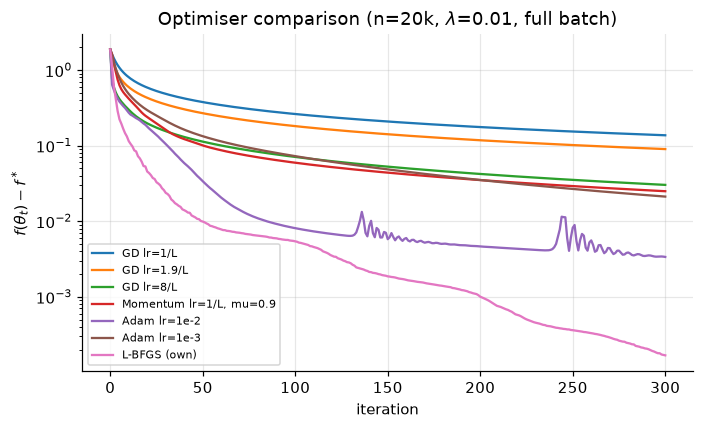

GD lr=1/L                    suboptimality after 300 its: 1.373e-01
GD lr=1.9/L                  suboptimality after 300 its: 9.015e-02
GD lr=8/L                    suboptimality after 300 its: 3.027e-02
Momentum lr=1/L, mu=0.9      suboptimality after 300 its: 2.496e-02
Adam lr=1e-2                 suboptimality after 300 its: 3.368e-03
Adam lr=1e-3                 suboptimality after 300 its: 2.119e-02
L-BFGS (own)                 suboptimality after 300 its: 1.677e-04


In [9]:
steps = 300; curves = {}
def run(name, opt, steps=steps):
    rec = []; fun = fun20
    def log(s, th, f): rec.append(fun(th)[0] - f_star)
    th = fit_first_order(theta0, Xs20, ys20, LAM_DEMO, ce_loss_grad, opt, steps, log=log); curves[name] = np.array(rec)
run("GD lr=1/L", GD(1 / Lhat)); run("GD lr=1.9/L", GD(1.9 / Lhat)); run("GD lr=8/L", GD(8 / Lhat))
run("Momentum lr=1/L, mu=0.9", Momentum(1 / Lhat, 0.9)); run("Adam lr=1e-2", Adam(1e-2)); run("Adam lr=1e-3", Adam(1e-3))
lb_curve = np.array([h[1] - f_star for h in hist_ref[:steps + 1]]); curves["L-BFGS (own)"] = lb_curve
fig, ax = plt.subplots(figsize=(6.5, 4))
for k, v in curves.items(): ax.semilogy(np.maximum(v, 1e-12), label=k)
ax.set_xlabel("iteration"); ax.set_ylabel("$f(\\theta_t)-f^*$"); ax.set_title(f"Optimiser comparison (n=20k, $\\lambda$={LAM_DEMO:g}, full batch)"); ax.legend(fontsize=7)
savefig("fig01_optimisers"); plt.show()
RESULTS["optimisers"] = {k: float(v[-1]) for k, v in curves.items()}; RESULTS["optimisers"]["L"] = float(Lhat)
for k, v in curves.items(): print(f"{k:28s} suboptimality after {len(v)-1} its: {v[-1]:.3e}")


**Reading the figure.** With $\kappa\approx10^4$ plain GD is hopeless in 300 steps (sub-optimality 0.14 at $\eta=1/L$). Note that GD still converges at $\eta=8/L\gg2/L$ and does *better*: the bound $L$ uses $\lambda_{\max}(\mathrm{diag}(q)-qq^\top)\le\frac12$, attained only when two classes share all the mass – near the optimum most points are confidently classified, so the *actual* curvature is far smaller. $1/L$ is therefore a **safe** step, not an optimal one. Momentum (0.025) and Adam (0.0034) cope much better with the ill-conditioning, and L-BFGS (1.7·10⁻⁴) is by far the most efficient per iteration – the reason it is used wherever converged solutions are needed. (Adam with lr=1e-3 is 6× worse than with 1e-2: hyper-parameters matter. The periodic spikes of the lr=1e-2 curve are the usual sign of a step that is slightly too large for some directions – Adam does not decrease monotonically.)

### B.7 The model as a *family of functions*: random members, neighbourhoods, and the "Naive Update"
(Following spec §7.5–7.7.) Each $\theta\in\mathbb R^{7850}$ is one function. (a) **100 random members** (Gaussian weights) – how good are they and how different are they from each other (disagreement = fraction of validation points where predicted labels differ)? (b) **Neighbourhood of the trained $f^*$**: perturb $\theta^*$ by $\mathcal N(0,\sigma^2I)$ – "nearby" is defined in *parameter* space by $\sigma$ and measured in *function* space by disagreement. (c) **Naive Update**: propose 100 neighbours, move to the best one; compare with gradient descent **at equal compute** (a loss evaluation = 1 forward pass; a gradient step ≈ 3).

random functions from the family (100 each):
  init std=0.001: err 0.904±0.044, mean pairwise disagreement 0.899
  init std=0.01: err 0.904±0.038, mean pairwise disagreement 0.900
  init std=0.1: err 0.894±0.044, mean pairwise disagreement 0.901


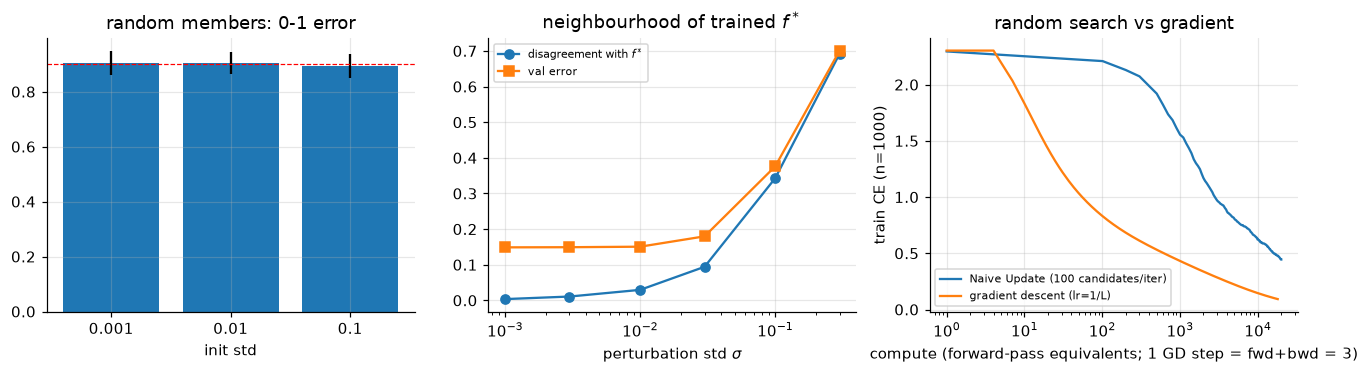

Naive Update after 200 iterations (20,000 forward passes): CE=0.445;  gradient descent after 200 steps (600 fwd-equiv.): CE=0.505;  after 6000 steps (18,000 fwd-equiv., equal compute): CE=0.0926  (start 2.295); #params=7850


In [10]:
Xv2, yv2 = Xva[:2000], yva[:2000]
r = np.random.default_rng(21)
fam_scales = [0.001, 0.01, 0.1]; fam = {}
for sc in fam_scales:
    ths = r.normal(size=(100, D * K + K)) * sc
    preds = np.stack([logits(t_, Xv2).argmax(1) for t_ in ths])                      # 100 x 2000 prediction matrix
    err = (preds != yv2).mean(1); dist = (preds[:, None, :] != preds[None, :, :]).mean(-1)
    fam[sc] = dict(err_mean=float(err.mean()), err_std=float(err.std()), mean_pair_disagreement=float(dist[np.triu_indices(100, 1)].mean()))
print("random functions from the family (100 each):"); [print(f"  init std={s}: err {v['err_mean']:.3f}±{v['err_std']:.3f}, mean pairwise disagreement {v['mean_pair_disagreement']:.3f}") for s, v in fam.items()]
# neighbourhood of a trained function
sig_list = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]; near = []
for sg in sig_list:
    ths = th_star + r.normal(size=(100, len(th_star))) * sg; preds = np.stack([logits(t_, Xv2).argmax(1) for t_ in ths]); ref = logits(th_star, Xv2).argmax(1)
    near.append(((preds != ref).mean(), (preds != yv2).mean()))
# "Naive Update": propose 100 nearby functions, keep the best on the training loss
nsub = np.random.default_rng(31).choice(len(ytr), 1000, replace=False); Xn, yn = Xtr[nsub], ytr[nsub]; fnn = make_objective(Xn, yn, 0.0, ce_loss_grad)
th_nv = r.normal(size=len(theta0)) * 0.001; nv_curve = [fnn(th_nv)[0]]; sg = 0.01
for it in range(200):
    cand = th_nv + r.normal(size=(100, len(th_nv))) * sg; fs = np.array([fnn(c)[0] for c in cand]); j = fs.argmin()
    if fs[j] < nv_curve[-1]: th_nv = cand[j]
    nv_curve.append(fnn(th_nv)[0])
Xan = np.hstack([Xn, np.ones((len(yn), 1))]); Ln = 0.5 * np.linalg.eigvalsh(Xan.T @ Xan / len(yn))[-1]
gd_curve = []; fit_first_order(np.zeros(len(theta0)), Xn, yn, 0.0, ce_loss_grad, GD(1.0 / Ln), 6000, log=lambda s, t_, f: gd_curve.append(f))   # 6000 GD steps ~ 18k forward-pass equivalents ~ 200 Naive-Update iterations x 100 candidates
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].bar([str(s) for s in fam_scales], [fam[s]["err_mean"] for s in fam_scales], yerr=[fam[s]["err_std"] for s in fam_scales]); ax[0].set_title("random members: 0-1 error"); ax[0].set_xlabel("init std"); ax[0].axhline(0.9, c="r", ls="--", lw=.8)
ax[1].plot(sig_list, [a for a, _ in near], "o-", label="disagreement with $f^*$"); ax[1].plot(sig_list, [b for _, b in near], "s-", label="val error"); ax[1].set_xscale("log"); ax[1].set_xlabel("perturbation std $\\sigma$"); ax[1].set_title("neighbourhood of trained $f^*$"); ax[1].legend(fontsize=7)
ax[2].semilogx(100 * np.arange(len(nv_curve)) + 1, nv_curve, label="Naive Update (100 candidates/iter)"); ax[2].semilogx(3 * np.arange(len(gd_curve)) + 1, gd_curve, label="gradient descent (lr=1/L)"); ax[2].set_xlabel("compute (forward-pass equivalents; 1 GD step = fwd+bwd = 3)"); ax[2].set_ylabel("train CE (n=1000)"); ax[2].set_title("random search vs gradient"); ax[2].legend(fontsize=7)
savefig("fig02_family"); plt.show()
RESULTS["family"] = dict(random={str(k): v for k, v in fam.items()}, neighbourhood=[dict(sigma=s, disagreement=float(a), val_err=float(b)) for s, (a, b) in zip(sig_list, near)],
                         naive_final=float(nv_curve[-1]), gd_at_200_steps=float(gd_curve[200]), gd_equal_compute=float(gd_curve[-1]), n_params=len(theta0))
print(f"Naive Update after 200 iterations (20,000 forward passes): CE={nv_curve[-1]:.3f};  gradient descent after 200 steps (600 fwd-equiv.): CE={gd_curve[200]:.3f};  after 6000 steps (18,000 fwd-equiv., equal compute): CE={gd_curve[-1]:.4f}  (start {nv_curve[0]:.3f}); #params={len(theta0)}")


**Reading the figure.** Random members are at chance (error ≈ 0.90, disagreeing with each other on ≈ 90 % of points, i.e. essentially independent guessers), whatever the initial scale – the vast majority of the family is useless; the useful functions form a tiny region. Around $f^*$, predictions are stable for $\sigma\lesssim0.01$ and degrade quickly beyond – training places us in a *basin*. The Naive Update is surprisingly effective per *iteration* (CE 0.445 after 200 iterations) but each iteration costs 100 forward passes; **at equal compute (≈ 18–20k forward-pass equivalents) gradient descent reaches CE 0.093 vs 0.445** (right panel), because one gradient step uses the information of all 7,850 directions at once whereas random search samples 100 of them – the gap grows with dimension.

---
# C. Evaluation and refinement

### C.0 Evaluation protocol (decided *before* looking at test data)
* **Splits:** 50k train / 10k validation / 10k test (official). The test set is used **once**, after all choices ($\lambda$, $T$, loss) are frozen.
* **Model selection:** stratification-free **5-fold cross-validation** on a 20k subset of the training set over $\lambda\in\{10^{-6},\dots,10^{-1}\}$ with *converged* L-BFGS fits; selection by mean CV cross-entropy (a proper scoring rule – smoother and more informative than 0-1 error, see C.3), also reporting CV error. All numbers are mean ± sample std over folds.
* **Metrics and why:** *0-1 error / accuracy* – the task objective (classes are balanced, so accuracy is not misleading); *macro-F1 and per-class P/R/F1 + confusion matrix* – expose class-specific failures hidden by the average; *cross-entropy* – the training loss, a proper scoring rule for the probabilities; *Brier score* – a second, bounded proper score; *ECE* (15 bins) – calibration, i.e. whether "0.8 confident" means 80 % correct. **Baselines:** majority class (10 %), nearest-class-mean (a no-training-needed linear classifier). **Uncertainty:** bootstrap 95 % CI on the test error.
* **Expected behaviour:** for a test image the model should put most mass on the true garment and the mass on the others should reflect visual similarity. Ideally the comparison model-vs-truth would be the 0-1 loss; it is **not** used for training because it is piecewise-constant (zero gradient a.e.) and NP-hard to minimise directly for linear classes – so we train a *convex surrogate* and **measure the task objective separately on validation/test** (the ideal comparison appears at validation and test stages only).

### C.1 Choosing the regularisation strength by cross-validation

CV time 135s
  lambda |            CV CE |         CV error |  train CE
   1e-06 | 0.6813 ± 0.0403 | 0.1809 ± 0.0083 | 0.2405
   1e-05 | 0.6655 ± 0.0280 | 0.1808 ± 0.0065 | 0.2397
   1e-04 | 0.6159 ± 0.0345 | 0.1768 ± 0.0074 | 0.2424
   1e-03 | 0.4771 ± 0.0219 | 0.1605 ± 0.0076 | 0.2798
   1e-02 | 0.4353 ± 0.0145 | 0.1495 ± 0.0088 | 0.3630
   1e-01 | 0.5044 ± 0.0112 | 0.1651 ± 0.0082 | 0.4841
lambda* (CV CE) = 0.01 | lambda minimising CV error = 0.01


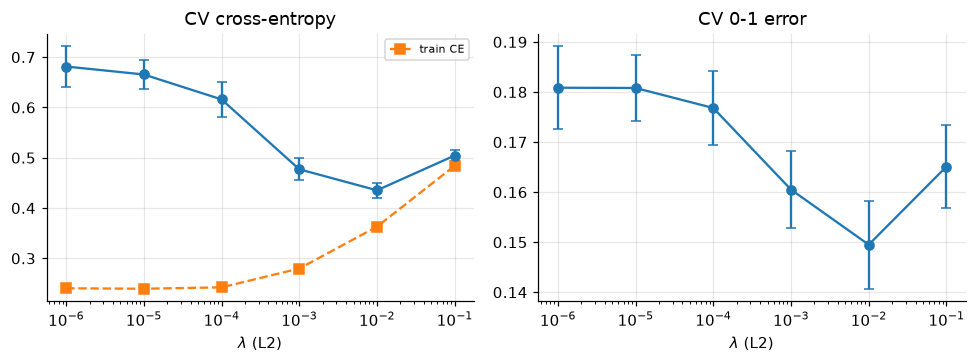

In [11]:
LAMS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]; FOLDS = 5
cvsub = np.random.default_rng(41).choice(len(ytr), 20_000, replace=False); Xc, yc = Xtr[cvsub], ytr[cvsub]
folds = np.array_split(np.random.default_rng(42).permutation(len(yc)), FOLDS); cv = {lam: [] for lam in LAMS}; t = time.time()
for lam in LAMS:
    for k in range(FOLDS):
        va = folds[k]; trn = np.concatenate([folds[j] for j in range(FOLDS) if j != k])
        th, *_ = lbfgs(make_objective(Xc[trn], yc[trn], lam, ce_loss_grad), theta0, maxiter=150)
        m = evaluate(logits(th, Xc[va]), yc[va]); mt = evaluate(logits(th, Xc[trn]), yc[trn]); m["train_ce"] = mt["ce"]; m["train_err"] = mt["err"]; cv[lam].append(m)
print(f"CV time {time.time()-t:.0f}s"); print(f"{'lambda':>8} | {'CV CE':>16} | {'CV error':>16} | {'train CE':>9}")
cv_tab = {}
for lam in LAMS:
    ce_ = np.array([m["ce"] for m in cv[lam]]); er_ = np.array([m["err"] for m in cv[lam]]); tce = np.mean([m["train_ce"] for m in cv[lam]])
    cv_tab[lam] = dict(ce_mean=ce_.mean(), ce_std=ce_.std(ddof=1), err_mean=er_.mean(), err_std=er_.std(ddof=1), train_ce=tce)
    print(f"{lam:8.0e} | {ce_.mean():.4f} ± {ce_.std(ddof=1):.4f} | {er_.mean():.4f} ± {er_.std(ddof=1):.4f} | {tce:.4f}")
LAM_STAR = min(LAMS, key=lambda l: cv_tab[l]["ce_mean"]); LAM_ERR = min(LAMS, key=lambda l: cv_tab[l]["err_mean"])
print("lambda* (CV CE) =", LAM_STAR, "| lambda minimising CV error =", LAM_ERR)
RESULTS["cv"] = dict(table={f"{l:g}": {k: float(v) for k, v in cv_tab[l].items()} for l in LAMS}, lam_star=LAM_STAR, lam_err=LAM_ERR, folds=FOLDS, n=len(yc))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a, key, lab in [(ax[0], "ce", "CV cross-entropy"), (ax[1], "err", "CV 0-1 error")]:
    a.errorbar(LAMS, [cv_tab[l][key + "_mean"] for l in LAMS], yerr=[cv_tab[l][key + "_std"] for l in LAMS], fmt="o-", capsize=3); a.set_xscale("log"); a.set_xlabel("$\\lambda$ (L2)"); a.set_title(lab)
ax[0].plot(LAMS, [cv_tab[l]["train_ce"] for l in LAMS], "s--", label="train CE"); ax[0].legend(fontsize=7)
savefig("fig03_cv"); plt.show()


**Reading the output.** Cross-validated CE is minimised at $\lambda^\*=10^{-2}$ (0.435 ± 0.015) and so is CV error (0.150 ± 0.009); the same $\lambda$ wins under both criteria. The U-shape is the classical bias–variance trade-off: small $\lambda$ gives a lower *training* CE (0.24) but a much higher CV CE (0.68) – a gap of 0.44 nats; large $\lambda$ under-fits (train and CV CE both ≈ 0.5). Note the fold-to-fold std (≈ 0.008 in error) is comparable to the differences between neighbouring small $\lambda$'s ($10^{-6}$ vs $10^{-5}$: 0.1809 vs 0.1808) – those are *not* distinguishable, whereas $10^{-2}$ vs $10^{-4}$ (≈ 2.7 pp) is.

### C.2 Loss vs. task objective (1): training dynamics – how tightly do CE and 0-1 error move together?
Small training set (n=2,000), $\lambda=0$, Adam – a regime that over-fits quickly. We track train/validation CE and error at every step.

val CE minimal at step 70 (CE=0.548, err=0.182);  val error minimal at step 79 (err=0.180, CE=0.550);  final: CE=0.884, err=0.206
relative increase after the optimum: val CE +61%, val error +15%


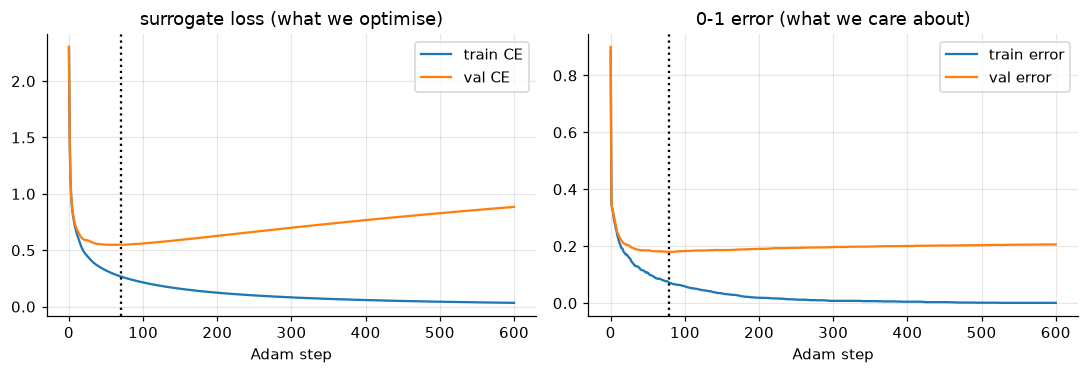

In [12]:
n_small = 2000; Xs5, ys5 = Xtr[:n_small], ytr[:n_small]; H_ = []
def log_dec(s, th, f):
    W, b = unpack(th); Ztr = Xs5 @ W + b; Zva = Xva @ W + b; a = evaluate(Ztr, ys5); v = evaluate(Zva, yva); H_.append((s, a["ce"], a["err"], v["ce"], v["err"], np.linalg.norm(W)))
fit_first_order(theta0, Xs5, ys5, 0.0, ce_loss_grad, Adam(3e-3), 600, log=log_dec); H_ = np.array(H_)
e_ce, e_err = int(H_[:, 3].argmin()), int(H_[:, 4].argmin())
print(f"val CE minimal at step {e_ce} (CE={H_[e_ce,3]:.3f}, err={H_[e_ce,4]:.3f});  val error minimal at step {e_err} (err={H_[e_err,4]:.3f}, CE={H_[e_err,3]:.3f});  final: CE={H_[-1,3]:.3f}, err={H_[-1,4]:.3f}")
print(f"relative increase after the optimum: val CE +{(H_[-1,3]/H_[e_ce,3]-1):.0%}, val error +{(H_[-1,4]/H_[e_err,4]-1):.0%}")
RESULTS["decoupling"] = dict(rel_ce_increase=float(H_[-1,3]/H_[e_ce,3]-1), rel_err_increase=float(H_[-1,4]/H_[e_err,4]-1), n=n_small, step_min_val_ce=e_ce, val_ce_min=float(H_[e_ce, 3]), val_err_at_min_ce=float(H_[e_ce, 4]), step_min_val_err=e_err,
                             val_err_min=float(H_[e_err, 4]), val_ce_at_min_err=float(H_[e_err, 3]), final_val_ce=float(H_[-1, 3]), final_val_err=float(H_[-1, 4]), final_train_ce=float(H_[-1, 1]), final_train_err=float(H_[-1, 2]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(H_[:, 1], label="train CE"); ax[0].plot(H_[:, 3], label="val CE"); ax[0].axvline(e_ce, c="k", ls=":"); ax[0].set_title("surrogate loss (what we optimise)"); ax[0].set_xlabel("Adam step"); ax[0].legend()
ax[1].plot(H_[:, 2], label="train error"); ax[1].plot(H_[:, 4], label="val error"); ax[1].axvline(e_err, c="k", ls=":"); ax[1].set_title("0-1 error (what we care about)"); ax[1].set_xlabel("Adam step"); ax[1].legend()
savefig("fig04_decoupling"); plt.show()


**Reading the figure.** Training CE keeps falling to ≈ 0.03 and training error reaches 0.1 %, while validation CE bottoms out at step 70 (0.548) and then *rises by 61 %* (to 0.884); validation error also deteriorates, but by only 15 % (0.180 → 0.206). So over-fitting is visible in both, but the surrogate **exaggerates** it: CE punishes the growing over-confidence of the *wrong* predictions, whereas error only registers a change when an argmax flips. The two minima are close (step 70 vs 79) here – the stronger decoupling shows up when we change calibration without changing decisions (C.7). A practical consequence: *early-stopping on validation CE would have stopped ~10 steps before the error optimum* – harmless here, but not guaranteed in general.

### C.3 Loss vs. task objective (2): optimisation as an implicit regulariser (H3)
On a *separable* sample (n=500, 784 features) with $\lambda=0$, the CE infimum is 0 but is only approached as $\|W\|\to\infty$. Theory (Soudry et al. 2018) predicts $\|W(t)\|\sim c\ln t$ and a normalised margin $\min_i(z_{y_i}-\max_{j\neq y_i}z_j)/\|W\|$ that increases towards the hard-margin SVM value. Plain GD with $\eta=1/L$ for 40,000 steps:

(28s) n=500, lambda=0: train error -> 0.000, loss -> 0.0047; ||W|| = 1.24 ln t + -6.25 (R^2=0.9994, t>=1000); normalised margin -0.1850 -> 0.5019


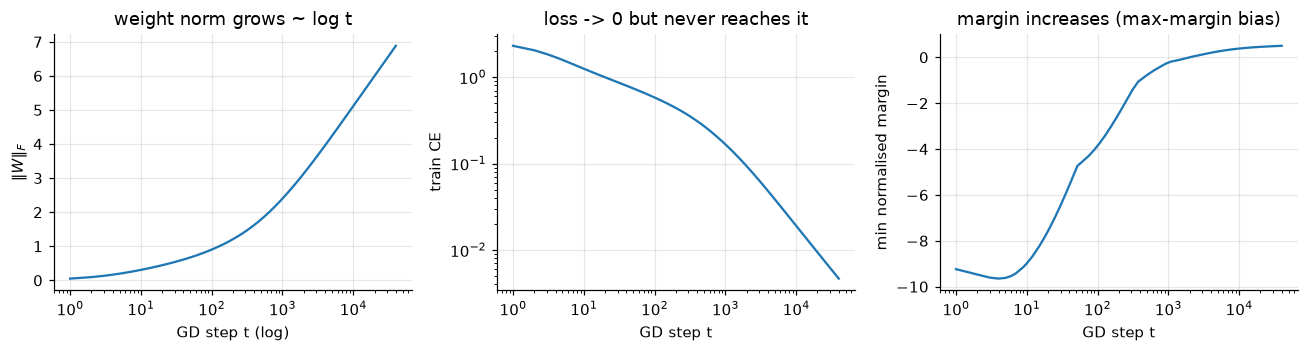

In [13]:
Xb, yb = Xtr[:500], ytr[:500]; Xab = np.hstack([Xb, np.ones((500, 1))]); Lb = 0.5 * np.linalg.eigvalsh(Xab.T @ Xab / 500)[-1]
logsteps = set(np.unique(np.round(np.logspace(0, np.log10(40000), 60)).astype(int))); R_ = []
def log_ib(s, th, f):
    if s in logsteps:
        W, b = unpack(th); Z = Xb @ W + b; zy = Z[np.arange(500), yb]; Zo = Z.copy(); Zo[np.arange(500), yb] = -np.inf
        R_.append((s, f, (Z.argmax(1) != yb).mean(), np.linalg.norm(W), (zy - Zo.max(1)).min() / np.linalg.norm(W)))
t = time.time(); fit_first_order(theta0, Xb, yb, 0.0, ce_loss_grad, GD(1.0 / Lb), 40000, log=log_ib); R_ = np.array(R_)
sl = R_[:, 0] >= 1000; coef = np.polyfit(np.log(R_[sl, 0]), R_[sl, 3], 1); pred_ = np.polyval(coef, np.log(R_[sl, 0])); r2 = 1 - ((R_[sl, 3] - pred_) ** 2).sum() / ((R_[sl, 3] - R_[sl, 3].mean()) ** 2).sum()
print(f"({time.time()-t:.0f}s) n=500, lambda=0: train error -> {R_[-1,2]:.3f}, loss -> {R_[-1,1]:.4f}; ||W|| = {coef[0]:.2f} ln t + {coef[1]:.2f} (R^2={r2:.4f}, t>=1000); normalised margin {R_[sl][0,4]:.4f} -> {R_[-1,4]:.4f}")
RESULTS["implicit_bias"] = dict(final_loss=float(R_[-1, 1]), final_train_err=float(R_[-1, 2]), slope_norm_vs_logt=float(coef[0]), r2=float(r2), margin_start=float(R_[sl][0, 4]), margin_end=float(R_[-1, 4]), steps=40000)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].semilogx(R_[:, 0], R_[:, 3]); ax[0].set_xlabel("GD step t (log)"); ax[0].set_ylabel("$\\|W\\|_F$"); ax[0].set_title("weight norm grows ~ log t")
ax[1].loglog(R_[:, 0], R_[:, 1]); ax[1].set_xlabel("GD step t"); ax[1].set_ylabel("train CE"); ax[1].set_title("loss -> 0 but never reaches it")
ax[2].semilogx(R_[:, 0], R_[:, 4]); ax[2].set_xlabel("GD step t"); ax[2].set_ylabel("min normalised margin"); ax[2].set_title("margin increases (max-margin bias)")
savefig("fig05_implicit_bias"); plt.show()


**Reading the figure.** $\|W\|_F$ is almost perfectly linear in $\ln t$ ($\|W\|=1.24\ln t-6.25$, $R^2=0.9994$ for $t\ge10^3$), the training error is 0 and the loss decays towards zero (0.0047 after 40k steps) *without ever reaching it*, and the normalised margin rises from negative (not yet separating) to 0.50. This reproduces the Soudry et al. prediction: with $\lambda=0$ the "solution" depends on **how long we run**, and the iterate drifts toward the max-margin direction. It also explains *why $\lambda>0$ is needed for a well-posed optimum* and why early stopping is a regulariser (H3 supported).

### C.4 Generalisation: testing the norm-based bound (H1)
For norm-bounded linear predictors with $\|W\|_F\le B$, $\|x\|\le R$, and a Lipschitz loss, the Rademacher complexity — hence the generalisation gap — scales like $BR/\sqrt n$ (independent of the 7,850 parameters). I sweep $n\in\{500,\dots,50{,}000\}$ and $\lambda\in\{10^{-4},10^{-3},10^{-2}\}$ (2 data-subsets for $n\le10^4$; $R=\max_i\|\tilde x_i\|$ over the training set) and relate the *observed* gap (val − train) to the *plug-in* quantity $\|\hat W\|_FR/\sqrt n$. The bound is an upper bound with unknown constants, so the test is of **shape** (monotone relation, slope ≈ 1 on log–log), not of equality.

generalisation sweep 68s, 36 fits
Spearman(proxy, CE gap)=0.989, Spearman(proxy, error gap)=0.865; log-log slopes: CE gap 1.04, error gap 0.78; error gap vs n slope -0.58


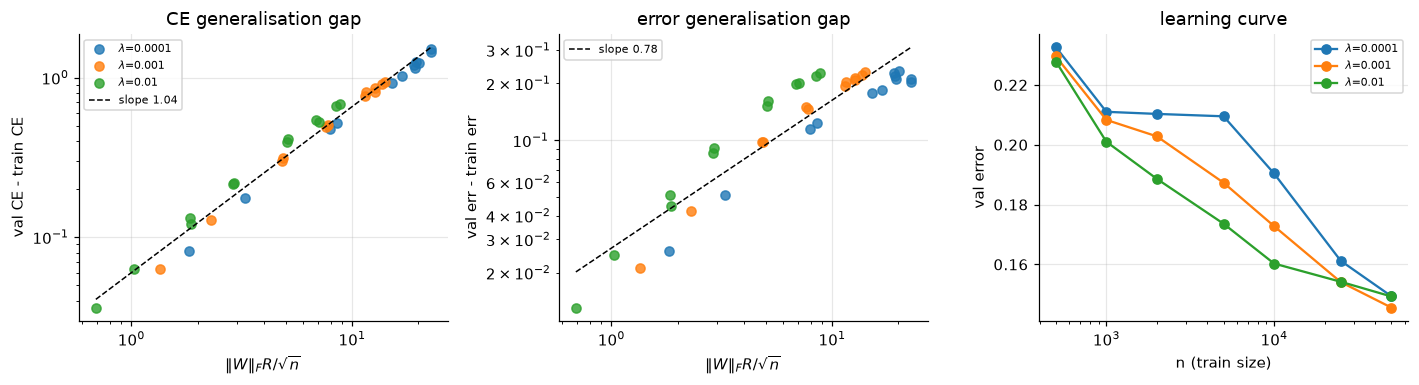

In [14]:
NS = [500, 1000, 2000, 5000, 10000, 25000, 50000]; GL = [1e-4, 1e-3, 1e-2]; gap_rows = []; t = time.time()
Rmax = float(np.linalg.norm(Xtr, axis=1).max())
for seed in [0, 1]:
    for n in NS:
        if seed == 1 and n > 10000: continue
        idx = np.random.default_rng(100 + seed).choice(len(ytr), n, replace=False)
        for lam in GL:
            th, *_ = lbfgs(make_objective(Xtr[idx], ytr[idx], lam, ce_loss_grad), theta0, maxiter=100)
            a = evaluate(logits(th, Xtr[idx]), ytr[idx]); v = evaluate(logits(th, Xva), yva); Wn = np.linalg.norm(unpack(th)[0])
            gap_rows.append(dict(n=n, lam=lam, seed=seed, W=Wn, proxy=Wn * Rmax / np.sqrt(n), ce_gap=v["ce"] - a["ce"], err_gap=v["err"] - a["err"], val_err=v["err"], val_ce=v["ce"]))
print(f"generalisation sweep {time.time()-t:.0f}s, {len(gap_rows)} fits")
from scipy.stats import spearmanr
pr = np.array([g["proxy"] for g in gap_rows]); cg = np.array([g["ce_gap"] for g in gap_rows]); eg = np.array([g["err_gap"] for g in gap_rows])
ok = (eg > 0) & (cg > 0)
sl_ce = np.polyfit(np.log(pr[ok]), np.log(cg[ok]), 1); sl_er = np.polyfit(np.log(pr[ok]), np.log(eg[ok]), 1)
rho_ce, rho_er = spearmanr(pr, cg)[0], spearmanr(pr, eg)[0]
ns_arr = np.array([g["n"] for g in gap_rows]); slope_n = np.polyfit(np.log(ns_arr[(ns_arr >= 1000) & ok]), np.log(eg[(ns_arr >= 1000) & ok]), 1)[0]
print(f"Spearman(proxy, CE gap)={rho_ce:.3f}, Spearman(proxy, error gap)={rho_er:.3f}; log-log slopes: CE gap {sl_ce[0]:.2f}, error gap {sl_er[0]:.2f}; error gap vs n slope {slope_n:.2f}")
RESULTS["generalisation"] = dict(spearman_ce=float(rho_ce), spearman_err=float(rho_er), slope_ce=float(sl_ce[0]), slope_err=float(sl_er[0]), slope_err_vs_n=float(slope_n), Rmax=Rmax, rows=gap_rows)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6)); cols = {1e-4: "C0", 1e-3: "C1", 1e-2: "C2"}
for lam in GL:
    m = np.array([g["lam"] == lam for g in gap_rows])
    ax[0].loglog(pr[m], cg[m], "o", c=cols[lam], label=f"$\\lambda$={lam:g}", alpha=.8); ax[1].loglog(pr[m & ok], eg[m & ok], "o", c=cols[lam], alpha=.8)
for a, s, ttl, yl in [(ax[0], sl_ce, "CE generalisation gap", "val CE - train CE"), (ax[1], sl_er, "error generalisation gap", "val err - train err")]:
    xs_ = np.logspace(np.log10(pr.min()), np.log10(pr.max()), 20); a.loglog(xs_, np.exp(s[1]) * xs_ ** s[0], "k--", lw=1, label=f"slope {s[0]:.2f}"); a.set_xlabel("$\\|W\\|_F R/\\sqrt{n}$"); a.set_ylabel(yl); a.set_title(ttl)
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
for lam in GL:
    for seed in [0]:
        rows = [g for g in gap_rows if g["lam"] == lam and g["seed"] == seed]; ax[2].semilogx([g["n"] for g in rows], [g["val_err"] for g in rows], "o-", c=cols[lam], label=f"$\\lambda$={lam:g}")
ax[2].set_xlabel("n (train size)"); ax[2].set_ylabel("val error"); ax[2].set_title("learning curve"); ax[2].legend(fontsize=7)
savefig("fig06_generalisation"); plt.show()


**Reading the output.** The plug-in complexity $\|\hat W\|_FR/\sqrt n$ is an excellent *predictor* of the gap: Spearman ρ = 0.99 with the CE gap and 0.87 with the error gap; on log–log axes the CE gap has slope 1.04 (≈ the linear scaling the bound has in this quantity) and the error gap 0.78 (error gaps are smaller and noisier; a slope below 1 is plausible but I have not tested why). The error gap falls like $n^{-0.58}$ in $n$ (the rate $n^{-1/2}$ of the bound is within the noise of a 2-seed sweep). Parameter count is *constant* (7,850) across all points, yet the gap varies by orders of magnitude – so the norm, not the dimension, drives generalisation (H1 supported). **Caveat:** this is correlation between a data-dependent *proxy* and the gap, not a verification of the bound's constants; the bound is also vacuous in absolute terms for these $B,R$.

### C.5 Customising the loss: robustness to label noise (H4)
CE is unbounded: one wrong label can contribute an arbitrarily large loss and gradient. I corrupt training labels symmetrically (with prob. 0 or 0.4 a label is replaced by a uniformly random *other* class), train on $n=3000$ points with the same optimiser, budget and regulariser grid for **CE** and **GCE ($q=0.7$, $q=0.3$)**, and measure error on the **clean** official test set (5 seeds, mean ± std). Both λ values are shown so that the comparison is not an artefact of one regularisation setting.

noise sweep 120s
noise 0% | lambda=0.001 | CE         | clean test error 0.2009 ± 0.0039
noise 0% | lambda=0.001 | GCE q=0.7  | clean test error 0.1842 ± 0.0016
noise 0% | lambda=0.001 | GCE q=0.3  | clean test error 0.1931 ± 0.0034
noise 0% | lambda=0.01 | CE         | clean test error 0.1954 ± 0.0036
noise 0% | lambda=0.01 | GCE q=0.7  | clean test error 0.1878 ± 0.0053
noise 0% | lambda=0.01 | GCE q=0.3  | clean test error 0.1877 ± 0.0032
noise 40% | lambda=0.001 | CE         | clean test error 0.4053 ± 0.0204
noise 40% | lambda=0.001 | GCE q=0.7  | clean test error 0.2267 ± 0.0033
noise 40% | lambda=0.001 | GCE q=0.3  | clean test error 0.3717 ± 0.0196
noise 40% | lambda=0.01 | CE         | clean test error 0.3492 ± 0.0187
noise 40% | lambda=0.01 | GCE q=0.7  | clean test error 0.2176 ± 0.0112
noise 40% | lambda=0.01 | GCE q=0.3  | clean test error 0.2953 ± 0.0208


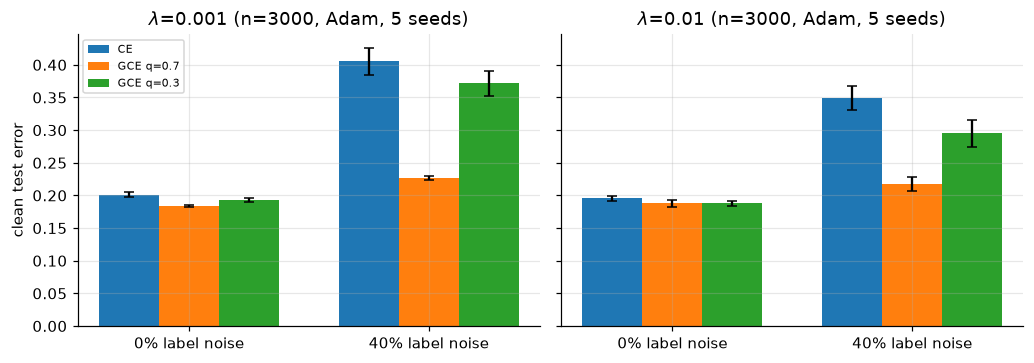

In [15]:
def flip_labels(y, rate, rng):
    y = y.copy(); m = rng.random(len(y)) < rate; y[m] = (y[m] + rng.integers(1, K, m.sum())) % K; return y     # uniform symmetric noise to another class
noise_rows = []; t = time.time()
for rate in [0.0, 0.4]:
  for lam_n in [1e-3, 1e-2]:
    for loss_name, lg in [("CE", ce_loss_grad), ("GCE q=0.7", lambda Z, y: gce_loss_grad(Z, y, 0.7)), ("GCE q=0.3", lambda Z, y: gce_loss_grad(Z, y, 0.3))]:
        for seed in range(5):
            r_ = np.random.default_rng(500 + seed); idx = r_.choice(len(ytr), 3000, replace=False); yn_ = flip_labels(ytr[idx], rate, r_)
            hist_ = []
            def lg_log(s, th, f):
                if s % 30 == 0: hist_.append((s, evaluate(logits(th, Xva), yva)["err"]))
            th = fit_first_order(theta0, Xtr[idx], yn_, lam_n, lg, Adam(2e-3), 2400, batch_size=64, rng=r_, log=lg_log)
            te = evaluate(logits(th, Xte), yte); noise_rows.append(dict(rate=rate, lam=lam_n, loss=loss_name, seed=seed, test_err=te["err"], best_val_err=min(h[1] for h in hist_), final_val_err=hist_[-1][1]))
print(f"noise sweep {time.time()-t:.0f}s")
noise_tab = {}
for rate in [0.0, 0.4]:
    for lam_n in [1e-3, 1e-2]:
        for ln in ["CE", "GCE q=0.7", "GCE q=0.3"]:
            e = np.array([g["test_err"] for g in noise_rows if g["rate"] == rate and g["loss"] == ln and g["lam"] == lam_n]); noise_tab[f"{rate}|{lam_n:g}|{ln}"] = (e.mean(), e.std(ddof=1))
            print(f"noise {rate:.0%} | lambda={lam_n:g} | {ln:10s} | clean test error {e.mean():.4f} ± {e.std(ddof=1):.4f}")
RESULTS["noise"] = {k: dict(mean=float(v[0]), std=float(v[1])) for k, v in noise_tab.items()}
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True); w = .25
for a, lam_n in zip(ax, [1e-3, 1e-2]):
    for i, ln in enumerate(["CE", "GCE q=0.7", "GCE q=0.3"]):
        a.bar(np.arange(2) + i * w, [noise_tab[f"{r}|{lam_n:g}|{ln}"][0] for r in [0.0, 0.4]], w, yerr=[noise_tab[f"{r}|{lam_n:g}|{ln}"][1] for r in [0.0, 0.4]], capsize=3, label=ln)
    a.set_xticks(np.arange(2) + w); a.set_xticklabels(["0% label noise", "40% label noise"]); a.set_title(f"$\\lambda$={lam_n:g} (n=3000, Adam, 5 seeds)")
ax[0].set_ylabel("clean test error"); ax[0].legend(fontsize=7)
savefig("fig07_noise"); plt.show()


**Reading the output.** With **40 % symmetric label noise**, GCE ($q=0.7$) gives a clean-test error of 0.218–0.227 against **0.349–0.405 for CE** (differences of 13–18 pp, several standard deviations across the 5 seeds), at both regularisation levels – regularising CE helps (0.405→0.349) but does not close the gap. On **clean labels** the cost is nil or negative: at $\lambda=10^{-2}$ CE 0.195 ± 0.004 vs GCE 0.188 ± 0.005/0.003, while at $\lambda=10^{-3}$ GCE($q$=0.7) is better (0.184 vs 0.201) – I attribute this to CE over-fitting on 3,000 points (bounded gradients act as a regulariser), *not* to GCE being intrinsically more accurate. $q=0.3$ is closer to CE and intermediate under noise, consistent with the interpolation $q\to0\Rightarrow$ CE. *Mechanism:* GCE's gradient is CE's re-weighted by $q_y^{\,q}$, so mislabelled points (where the model gives $q_y\approx0$) stop dominating the update. Limits: GCE is non-convex (no guarantee, no L-BFGS), final iterates (no early stopping) are reported, and noise is *symmetric* – the case where theory predicts robustness (Ghosh et al. 2017); class-dependent noise would be harder. H4 supported under these conditions.

### C.6 Final model, error analysis and baselines
$\lambda^\*$ from CV is used to train on all 50k training images; metrics are then reported on train / validation / **test**.

final fit: lambda=0.01, f=0.44260, |grad|=7.5e-05, 70s
train ce=0.3984 err=0.1352 macro_f1=0.8640 brier=0.1995 ece=0.0374
val   ce=0.4320 err=0.1473 macro_f1=0.8513 brier=0.2161 ece=0.0287
test  ce=0.4481 err=0.1595 macro_f1=0.8394 brier=0.2263 ece=0.0175


baselines (test error): majority=0.900, nearest-class-mean=0.323, softmax regression=0.160
test error 95% bootstrap CI: [0.1514, 0.1666]
  T-shirt     P=0.808 R=0.820 F1=0.814
  Trouser     P=0.979 R=0.951 F1=0.965
  Pullover    P=0.726 R=0.730 F1=0.728
  Dress       P=0.833 R=0.871 F1=0.852
  Coat        P=0.726 R=0.761 F1=0.743
  Sandal      P=0.926 R=0.915 F1=0.921
  Shirt       P=0.630 R=0.559 F1=0.592
  Sneaker     P=0.899 R=0.924 F1=0.911
  Bag         P=0.930 R=0.939 F1=0.934
  Ankle boot  P=0.934 R=0.935 F1=0.935
most frequent confusions (true -> predicted): [(np.int64(141), 'Shirt', 'T-shirt'), (np.int64(136), 'Pullover', 'Coat'), (np.int64(124), 'Shirt', 'Pullover'), (np.int64(110), 'Coat', 'Pullover'), (np.int64(108), 'Shirt', 'Coat')]


/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


reference MLP(256) test error 0.1212 (27s)


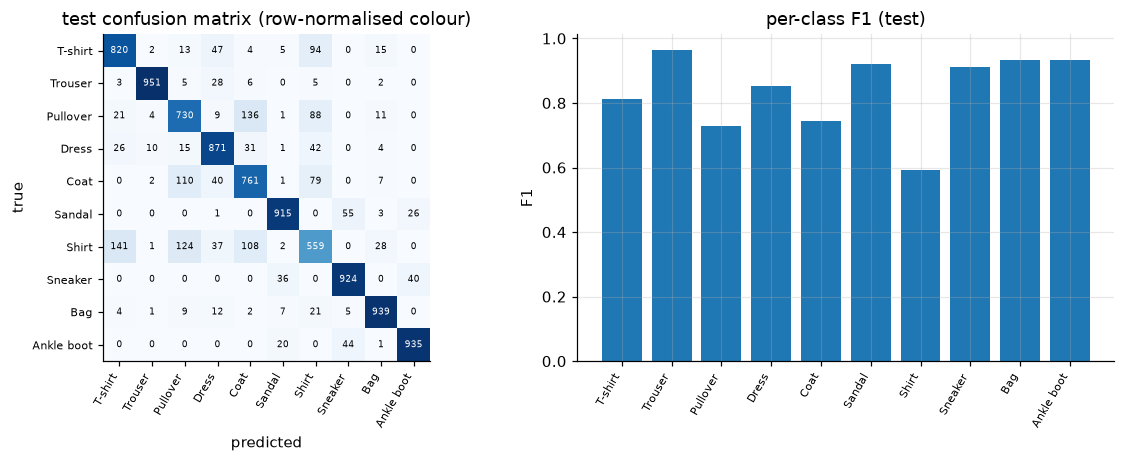

In [16]:
t = time.time(); th_fin, f_fin, g_fin, _ = lbfgs(make_objective(Xtr, ytr, LAM_STAR, ce_loss_grad), theta0, maxiter=800, gtol=1e-6)
print(f"final fit: lambda={LAM_STAR:g}, f={f_fin:.5f}, |grad|={np.linalg.norm(g_fin):.1e}, {time.time()-t:.0f}s")
Ztr_f, Zva_f, Zte_f = logits(th_fin, Xtr), logits(th_fin, Xva), logits(th_fin, Xte)
M = {"train": evaluate(Ztr_f, ytr), "val": evaluate(Zva_f, yva), "test": evaluate(Zte_f, yte)}
for k, v in M.items(): print(f"{k:5s} {fmt(v)}")
# baselines
maj = np.bincount(ytr).argmax(); base_maj = float((yte != maj).mean())
cent = np.stack([Xtr[ytr == k].mean(0) for k in range(K)]); ncm_err = float((np.argmin(((Xte[:, None, :] - cent[None]) ** 2).sum(-1), 1) != yte).mean())
print(f"baselines (test error): majority={base_maj:.3f}, nearest-class-mean={ncm_err:.3f}, softmax regression={M['test']['err']:.3f}")
# bootstrap CI on the test set
bs = np.random.default_rng(7); pred_te = Zte_f.argmax(1); errs = np.array([(pred_te[i] != yte[i]).mean() for i in [bs.integers(0, len(yte), len(yte)) for _ in range(1000)]])
ci = (float(np.percentile(errs, 2.5)), float(np.percentile(errs, 97.5))); print(f"test error 95% bootstrap CI: [{ci[0]:.4f}, {ci[1]:.4f}]")
cm = confusion(yte, pred_te); mf1, f1c, prc, rec = macro_f1(cm)
for k in range(K): print(f"  {CLASSES[k]:11s} P={prc[k]:.3f} R={rec[k]:.3f} F1={f1c[k]:.3f}")
off = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(K) for j in range(K) if i != j]; off.sort(reverse=True); print("most frequent confusions (true -> predicted):", off[:5])
RESULTS["final"] = dict(lam=LAM_STAR, metrics=M, majority_err=base_maj, ncm_err=ncm_err, ci95=ci, per_class={CLASSES[k]: dict(p=float(prc[k]), r=float(rec[k]), f1=float(f1c[k])) for k in range(K)}, top_confusions=[(int(a), b, c) for a, b, c in off[:5]])
# off-the-shelf modern alternative (reference only)
from sklearn.neural_network import MLPClassifier
t = time.time(); mlp = MLPClassifier((256,), max_iter=15, random_state=0).fit(Xtr, ytr); mlp_err = float((mlp.predict(Xte) != yte).mean()); print(f"reference MLP(256) test error {mlp_err:.4f} ({time.time()-t:.0f}s)"); RESULTS["final"]["mlp_err"] = mlp_err

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
im = ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues"); ax[0].set_xticks(range(K)); ax[0].set_yticks(range(K)); ax[0].set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=7); ax[0].set_yticklabels(CLASSES, fontsize=7)
for i in range(K):
    for j in range(K): ax[0].text(j, i, f"{cm[i,j]}", ha="center", va="center", fontsize=6, color="w" if cm[i, j] > 500 else "k")
ax[0].set_title("test confusion matrix (row-normalised colour)"); ax[0].grid(False); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true")
ax[1].bar(range(K), f1c); ax[1].set_xticks(range(K)); ax[1].set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=7); ax[1].set_ylabel("F1"); ax[1].set_title("per-class F1 (test)")
savefig("fig08_confusion"); plt.show()


**Reading the output.** The selected model reaches **15.95 % test error** (95 % bootstrap CI [15.1 %, 16.7 %]), macro-F1 0.839, vs **90.0 %** for the majority class and **32.3 %** for nearest-class-mean ⇒ the learning is real, and the CE-trained linear model beats a no-training linear classifier by 16 pp. The train–test error gap is 2.4 pp (13.5 % vs 15.95 %): mild over-fitting, as selected by CV. A reference one-hidden-layer MLP (256 units, sklearn, 15 epochs – **off-the-shelf, not my implementation, shown only for context**) reaches ≈ 12.1 %, so non-linear features are worth ≈ 4 pp: the *linear hypothesis space*, not the optimiser, is now the limit (approximation error dominates). **Per-class analysis:** Trouser (F1 0.965), Bag (0.935), Ankle boot (0.935) are easy; **Shirt (F1 0.592)** is the failure mode, confused with T-shirt (141), Pullover (124) and Coat (108); Pullover↔Coat (136/110) is next. These are exactly the visually similar upper-body classes anticipated in A.1, and errors are *systematic* (semantic neighbours), not random.

### C.7 Loss vs. task objective (3): calibration and temperature scaling
Because $\arg\max_k(z_k/T)=\arg\max_kz_k$ for every $T>0$, dividing the logits by a scalar **cannot change any decision** (error, F1, confusion matrix are unchanged) but changes the CE, Brier and ECE arbitrarily. Hence CE is *not* a function of the decisions alone. I fit $T$ on the validation set (minimising CE) and apply it to the test set – for the final model and for a deliberately over-fit one.

temperature T=0.891 (fit on validation)
 before: ce=0.4481 err=0.1595 macro_f1=0.8394 brier=0.2263 ece=0.0175
 after : ce=0.4463 err=0.1595 macro_f1=0.8394 brier=0.2255 ece=0.0084


overfit model (n=2000, lambda=0): T=44.519
 before: ce=16.0951 err=0.2283 macro_f1=0.7722 brier=0.4493 ece=0.2238
 after : ce=0.6646 err=0.2283 macro_f1=0.7722 brier=0.3210 ece=0.0126


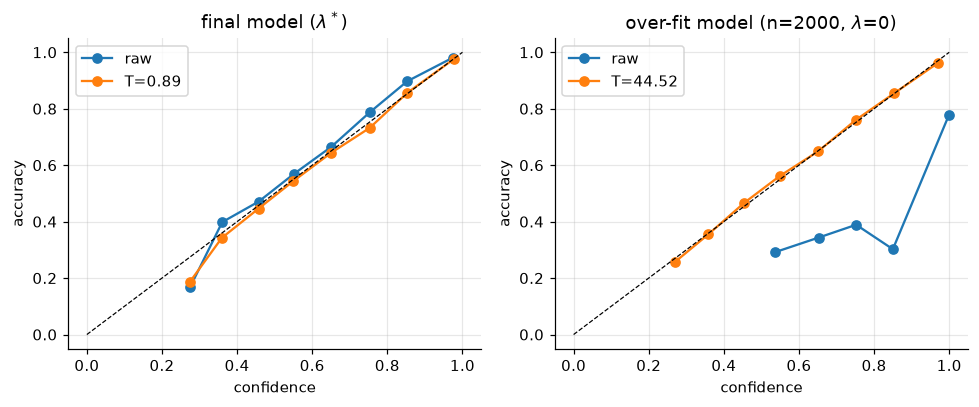

In [17]:
def fit_temperature(Z, y):
    grid = np.exp(np.linspace(np.log(0.2), np.log(100), 600)); ce = [evaluate(Z / T, y)["ce"] for T in grid]; return grid[int(np.argmin(ce))]
T_hat = fit_temperature(Zva_f, yva); Mt = evaluate(Zte_f / T_hat, yte); M0 = M["test"]
print(f"temperature T={T_hat:.3f} (fit on validation)\n before: {fmt(M0)}\n after : {fmt(Mt)}")
# the same model family overfit (lambda=1e-6, few training points) shows the effect much more strongly
th_over, *_ = lbfgs(make_objective(Xtr[:2000], ytr[:2000], 0.0, ce_loss_grad), theta0, maxiter=300); Zo_va, Zo_te = logits(th_over, Xva), logits(th_over, Xte)
T_over = fit_temperature(Zo_va, yva); Mo0, Mo1 = evaluate(Zo_te, yte), evaluate(Zo_te / T_over, yte)
print(f"overfit model (n=2000, lambda=0): T={T_over:.3f}\n before: {fmt(Mo0)}\n after : {fmt(Mo1)}")
RESULTS["calibration"] = dict(T=float(T_hat), before=M0, after=Mt, overfit=dict(T=float(T_over), before=Mo0, after=Mo1))
def reliability(P, y, bins=10):
    conf, pred = P.max(1), P.argmax(1); acc = (pred == y).astype(float); edges = np.linspace(0, 1, bins + 1); xs, ys_ = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() > 20: xs.append(conf[m].mean()); ys_.append(acc[m].mean())
    return xs, ys_
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, (Z_, T_, ttl) in zip(ax, [(Zte_f, T_hat, "final model ($\\lambda^*$)"), (Zo_te, T_over, "over-fit model (n=2000, $\\lambda$=0)")]):
    for Tv, lab in [(1.0, "raw"), (T_, f"T={T_:.2f}")]:
        xs_, ys_ = reliability(softmax(Z_ / Tv), yte); a.plot(xs_, ys_, "o-", label=lab)
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.set_xlabel("confidence"); a.set_ylabel("accuracy"); a.set_title(ttl); a.legend()
savefig("fig09_reliability"); plt.show()


**Reading the output.** For the final model the fitted $T=0.89$ (<1: slightly *under*-confident because the L2 penalty shrinks logits) lowers ECE from 0.0175 to 0.0084 with **identical error (15.95 %)**. For the over-fit model (n=2000, $\lambda=0$) the effect is dramatic: test **CE falls from 16.10 to 0.66** (24×), ECE from 0.224 to 0.013, with *exactly* the same 22.83 % error (its fitted $T=44.5$ – the model was ~45× over-confident). One scalar leaves the task objective untouched yet moves the surrogate by more than an order of magnitude: **low CE is not necessary for low error, and CE alone cannot rank two models' decision quality** (H2 supported). Temperature scaling is a cheap, post-hoc mitigation to *monitor and repair* this mismatch; note it requires a held-out set and does not fix wrong *decisions*.

### C.8 Where does the loss come from? (edge cases where loss and objective disagree)
The 0-1 error counts every mistake as 1; CE charges $-\log q_y$, so it is dominated by *confident* mistakes while *near-misses* ($q_y$ slightly below the max) are almost free.

share of the total test log-loss carried by the worst 5% / 10% / 20% of test points: 0.36 / 0.55 / 0.77
misclassified points with p_true>0.3 (near-misses; tiny loss cost): 0.28 of errors


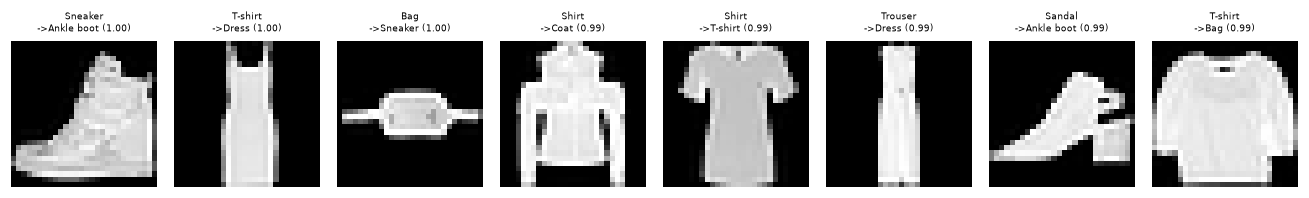

In [18]:
P_te = softmax(Zte_f); wrong = np.where(pred_te != yte)[0]; conf_w = P_te[wrong].max(1); top = wrong[np.argsort(-conf_w)[:8]]
pl = -np.log(np.maximum(P_te[np.arange(len(yte)), yte], 1e-300)); share = np.sort(pl)[::-1].cumsum() / pl.sum()
print(f"share of the total test log-loss carried by the worst 5% / 10% / 20% of test points: {share[int(.05*len(pl))]:.2f} / {share[int(.10*len(pl))]:.2f} / {share[int(.20*len(pl))]:.2f}")
print(f"misclassified points with p_true>0.3 (near-misses; tiny loss cost): {(P_te[wrong, yte[wrong]] > 0.3).mean():.2f} of errors")
RESULTS["loss_concentration"] = dict(top5=float(share[int(.05 * len(pl))]), top10=float(share[int(.10 * len(pl))]), top20=float(share[int(.20 * len(pl))]), near_miss_frac=float((P_te[wrong, yte[wrong]] > 0.3).mean()))
fig, ax = plt.subplots(1, 8, figsize=(12, 2.0))
for a, i in zip(ax, top): a.imshow(Xte_raw[i].reshape(28, 28), cmap="gray"); a.axis("off"); a.set_title(f"{CLASSES[yte[i]]}\n->{CLASSES[pred_te[i]]} ({P_te[i].max():.2f})", fontsize=6)
savefig("fig10_confident_errors"); plt.show()


**Reading the output.** The worst 5 % of test points carry **36 %** of the total test log-loss (10 % → 55 %, 20 % → 77 %): a small set of confident mistakes dominates the surrogate – the opposite of the 0-1 error, where each mistake counts once. At the other extreme **28 % of all errors are near-misses** ($q_{\rm true}>0.3$) that cost the surrogate little. Hence loss and objective can disagree *both ways*: an update that fixes a few confident outliers lowers CE a lot but error by 0.01 %; one that flips many near-misses lowers error but barely moves CE. The figure shows the eight most confident errors – they are mostly Shirt/T-shirt/Pullover/Coat pairs whose *labels* are arguably ambiguous, i.e. partly label noise rather than model failure (a further reason to consider the robust loss of C.5).

### C.9 A task-aligned metric: expected cost, and the Bayes-risk decision rule
In a catalogue-tagging use-case, calling a *Shirt* a *T-shirt* is a milder mistake than calling it a *Sandal*. I define an **illustrative (assumed, not measured) cost matrix** $C[j,k]$ = cost of predicting $k$ when the truth is $j$: 0 on the diagonal, **$c_{\rm in}$** for errors inside the semantic groups {T-shirt, Pullover, Coat, Shirt} and {Sandal, Sneaker, Ankle boot}, and 1 otherwise. The **Bayes-optimal decision** under model probabilities is $\hat y(x)=\arg\min_k\sum_jq_j(x)\,C[j,k]$ — which is only as good as the probabilities are calibrated (hence C.7). Sensitivity to the assumed $c_{\rm in}\in\{0.1,0.3,0.6\}$ is reported rather than a single hand-picked value.

in-group cost 0.1 | raw      | argmax: cost=0.0570 err=0.1595 | Bayes-risk rule: cost=0.0552 err=0.1618
in-group cost 0.1 | T-scaled | argmax: cost=0.0570 err=0.1595 | Bayes-risk rule: cost=0.0551 err=0.1610
in-group cost 0.3 | raw      | argmax: cost=0.0798 err=0.1595 | Bayes-risk rule: cost=0.0785 err=0.1609
in-group cost 0.3 | T-scaled | argmax: cost=0.0798 err=0.1595 | Bayes-risk rule: cost=0.0788 err=0.1606
in-group cost 0.6 | raw      | argmax: cost=0.1139 err=0.1595 | Bayes-risk rule: cost=0.1134 err=0.1599
in-group cost 0.6 | T-scaled | argmax: cost=0.1139 err=0.1595 | Bayes-risk rule: cost=0.1131 err=0.1595


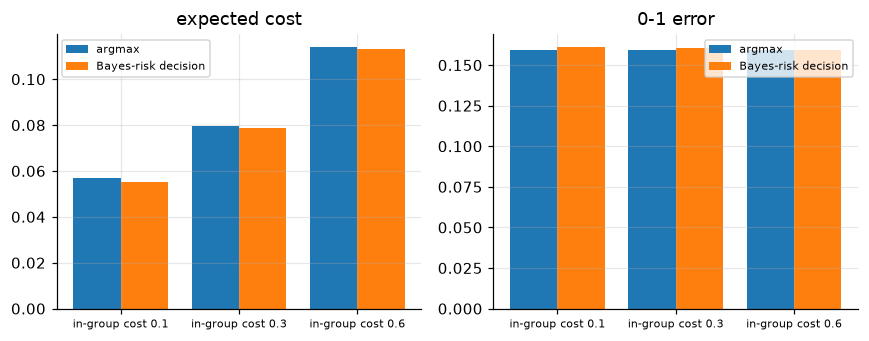

In [19]:
grp = {0: "top", 2: "top", 4: "top", 6: "top", 5: "shoe", 7: "shoe", 9: "shoe"}        # ASSUMED semantic groups (illustrative cost model)
def cost_matrix(c_in):
    C = np.ones((K, K)); np.fill_diagonal(C, 0.0)
    for i in range(K):
        for j in range(K):
            if i != j and i in grp and j in grp and grp[i] == grp[j]: C[i, j] = c_in
    return C
def bayes_decision(P, C): return np.argmin(P @ C, axis=1)          # argmin_k sum_j p_j C[j,k]  (minimum expected cost)
cs = {}
for c_in in [0.1, 0.3, 0.6]:
    C = cost_matrix(c_in)
    for name, Z_ in [("raw", Zte_f), ("T-scaled", Zte_f / T_hat)]:
        Pp = softmax(Z_); a_, b_ = Pp.argmax(1), bayes_decision(Pp, C)
        cs[f"{c_in}|{name}"] = dict(argmax_cost=float(C[yte, a_].mean()), bayes_cost=float(C[yte, b_].mean()), argmax_err=float((a_ != yte).mean()), bayes_err=float((b_ != yte).mean()))
        print(f"in-group cost {c_in} | {name:8s} | argmax: cost={cs[f'{c_in}|{name}']['argmax_cost']:.4f} err={cs[f'{c_in}|{name}']['argmax_err']:.4f} | Bayes-risk rule: cost={cs[f'{c_in}|{name}']['bayes_cost']:.4f} err={cs[f'{c_in}|{name}']['bayes_err']:.4f}")
RESULTS["cost_sensitive"] = cs
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2)); keys = [f"{c}|T-scaled" for c in [0.1, 0.3, 0.6]]
for a, key, ttl in [(ax[0], "cost", "expected cost"), (ax[1], "err", "0-1 error")]:
    a.bar(np.arange(3) - .2, [cs[k][f"argmax_{key}"] for k in keys], .4, label="argmax"); a.bar(np.arange(3) + .2, [cs[k][f"bayes_{key}"] for k in keys], .4, label="Bayes-risk decision")
    a.set_xticks(range(3)); a.set_xticklabels([f"in-group cost {c}" for c in [0.1, 0.3, 0.6]], fontsize=7); a.set_title(ttl); a.legend(fontsize=7)
savefig("fig11_cost"); plt.show()


**Reading the output (an honest, modest result).** Applying the minimum-expected-cost rule lowers the expected cost only slightly (e.g. 0.0570 → 0.0550 for $c_{\rm in}=0.1$, i.e. −3.5 %; 0.0797 → 0.0788 for 0.3; <1 % for 0.6) while the 0-1 error *rises* by 0–0.23 pp. So (i) the 0-1 error and the cost objective are genuinely different – the decision rule that is optimal for one is not for the other – but (ii) for *this* model the gain is small: softmax-regression posteriors are rarely ambiguous enough in the "wrong" direction for the rule to change many decisions, and most errors are already inside the cheap groups. The right conclusion is *not* that cost-sensitivity is useless, but that retraining with a cost-aware loss or richer features would be needed for a material gain. Results also depend on the assumed cost matrix, which is illustrative and was not measured from a real use-case.

In [20]:
with open("results_opt1.json", "w") as f: json.dump(RESULTS, f, indent=1, default=lambda o: float(o) if isinstance(o, (np.floating,)) else int(o) if isinstance(o, np.integer) else str(o))
print("saved results_opt1.json")


saved results_opt1.json


---
# D. Discussion, limitations and future work

**Answer to the research question.** Minimising cross-entropy *does* drive 0-1 error down (final test error 15.95 % vs 90 % chance), and the surrogate–objective gap is **controllable but real**: (H1) the generalisation gap tracks $\|W\|_FR/\sqrt n$ (Spearman 0.99 for the CE gap), not the parameter count; (H2) CE exaggerates over-fitting (+61 % vs +15 % for error) and can be changed 24× by a single scalar without changing any decision, so CE must be accompanied by decision-based metrics and a calibration check; (H3) with $\lambda=0$ the optimum is not attained – $\|W\|\propto\ln t$ – so optimisation time is a hidden hyper-parameter; (H4) a bounded, re-weighted CE (GCE) halves the error gap under 40 % label noise (0.22 vs 0.35–0.41) at no cost on clean data.

**Implications.** (i) Always select $\lambda$ on held-out data *with converged solvers* – otherwise early stopping confounds the comparison. (ii) Report error **and** a proper scoring rule **and** calibration; any one alone can mislead. (iii) Post-hoc temperature scaling is a cheap repair for the loss/objective mismatch; cost-aware *decisions* require good probabilities but gave only a small gain here.

**Limitations.** (1) *Linear hypothesis space*: ≈ 4 pp worse than a small MLP – approximation error, not estimation error, dominates at $n=50{,}000$; (2) results are on a single dataset (Fashion-MNIST) and a single random train/validation split for the final model (CV covers $\lambda$ only; the test CI reflects test-set sampling, not training-set variability); (3) the generalisation sweep tests the *shape* of the bound with a plug-in proxy, 2 seeds, and shows association, not a proof; (4) the cost matrix in C.9 is assumed; (5) GCE experiments use $n=3000$, symmetric noise, final iterates, and a non-convex objective (no global-optimum guarantee); (6) the decoupling demonstration uses one small-$n$ regime; (7) the standard deviations come from 5 folds / 5 seeds – small samples.

**Future work (derived from the observed failure modes).** *Architectural:* replace the linear map by random-feature/kernel or convolutional features – the confusion analysis (Shirt/T-shirt/Pullover/Coat, texture and sleeve-length cues) suggests local, translation-equivariant features would help most. *Algorithmic:* (a) a **temperature-/cost-aware training objective** (e.g. optimise CE + ECE-style penalty, or train directly with a margin loss) to close the loss–objective gap instead of repairing it post hoc; (b) a **per-class $q$ or noise-transition-matrix correction** for class-dependent label noise, motivated by the ambiguous Shirt labels; (c) test the **Soudry max-margin limit** against an explicit hard-margin multi-class SVM solution; (d) **second-order/pre-conditioned methods** (whitening via PCA) to attack the $\kappa\approx10^4$ conditioning directly; (e) estimate the bound's constants (e.g. empirical Rademacher complexity by Monte-Carlo sign flips) to test H1 quantitatively rather than by correlation.

### References
Bartlett & Mendelson (2002) *Rademacher and Gaussian complexities*, JMLR 3. · Bartlett, Jordan & McAuliffe (2006) *Convexity, classification and risk bounds*, JASA 101. · Berger, Della Pietra & Della Pietra (1996) *A maximum entropy approach to NLP*, Comput. Linguistics 22. · Berkson (1944) *Application of the logistic function to bio-assay*, JASA 39. · Bridle (1990) *Probabilistic interpretation of feed-forward classification network outputs…*, in Neurocomputing, Springer. · Cox (1958) *The regression analysis of binary sequences*, JRSS-B 20. · Ghosh, Kumar & Sastry (2017) *Robust loss functions under label noise for DNNs*, AAAI. · Guo, Pleiss, Sun & Weinberger (2017) *On calibration of modern neural networks*, ICML. · Jaynes (1957) *Information theory and statistical mechanics*, Phys. Rev. 106. · Kakade, Sridharan & Tewari (2008) *On the complexity of linear prediction*, NeurIPS. · Kingma & Ba (2015) *Adam*, ICLR. · Liu & Nocedal (1989) *On the limited memory BFGS method…*, Math. Programming 45. · McFadden (1974) *Conditional logit analysis of qualitative choice behavior*, in Frontiers in Econometrics. · Nocedal & Wright (2006) *Numerical Optimization*, 2nd ed. · Rosenblatt (1958) *The perceptron*, Psychol. Rev. 65. · Soudry, Hoffer, Nacson, Gunasekar & Srebro (2018) *The implicit bias of gradient descent on separable data*, JMLR 19. · Theil (1969) *A multinomial extension of the linear logit model*, Int. Econ. Rev. 10. · Xiao, Rasul & Vollgraf (2017) *Fashion-MNIST*, arXiv:1708.07747. · Zhang (2004) *Statistical behavior and consistency of classification methods based on convex risk minimization*, Ann. Stat. 32. · Zhang & Sabuncu (2018) *Generalized cross entropy loss for training deep neural networks with noisy labels*, NeurIPS.

*(Citations are from my reading list and from memory of the literature; bibliographic details should be double-checked against the originals before submission — see the Knowledge-Gaps section of the journal.)*

*Implementation log, AI-tool usage and knowledge gaps are documented in the accompanying journal PDF (required by the specification).*
